# Análisis de caracterización del actuador LPOA1S-EM-RT-PRE02

## a. Introducción y Objetivo

Este informe caracteriza el actuador **LPOA1S-EM-RT-PRE02** a partir de un ensayo de ciclos de subida y bajada a 6 velocidades comandadas (0.004, 0.008, 0.016, 0.032, 0.064 y 0.128 º/s).

**Objetivo:** determinar qué velocidad de operación es la más adecuada para este sistema, evaluando su precisión de seguimiento (error de velocidad), su repetibilidad (dispersión), y su comportamiento dinámico en el arranque y la frenada. La velocidad final propuesta se justifica en la sección de Conclusiones a partir de los resultados obtenidos.

## b. Datos y metodología

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Descripción de los datos

Datos de posición, velocidad y aceleración (comandadas y reales) muestreados a 0.1 s. **Unidades:** posición en grados [º], velocidad en grados/segundo [º/s], aceleración en grados/segundo² [º/s²], tiempo en segundos [ms]. Estas unidades se mantienen de forma consistente en todo el análisis.

In [2]:
df = pd.read_csv("LPOA1S-EM-RT-PRE02_MRP8080_m1.csv")
df.head()
df.tail()
df.info
df.describe()

,Time,SetPosition,ActualPosition,SetVelocity,ActualVelocity,SetAcceleration,ActualAcceleration
count,62218.000000,62218.000000,62218.000000,62218.000000,62218.000000,62218.000000,62218.0
mean,3110.850000,0.000006,-0.000007,-0.000313,-0.000153,-0.000867,0.0
std,1796.093386,0.089955,0.089955,0.012708,0.012698,0.182903,0.0
min,0.000000,-0.200001,-0.200038,-0.129000,-0.134000,-22.890000,0.0
25%,1555.425000,0.000000,-0.000014,0.000000,0.000000,0.000000,0.0
50%,3110.850000,0.000000,-0.000012,0.000000,0.000000,0.000000,0.0
75%,4666.275000,0.000000,-0.000010,0.000000,0.000000,0.000000,0.0
max,6221.700000,0.200000,0.200012,0.127000,0.130000,21.590000,0.0


### Preprocesado y segmentación

Ordenación temporal, cálculo del signo de movimiento, segmentación en tramos, asignación de ciclos y clasificación por velocidad comandada.

In [3]:
df=df.sort_values("Time").reset_index(drop=True) #ordenar los valores por tiempo
df["der_pos"]=df["SetPosition"].diff() #calcular der_pos, la derivada de SetPosition 
#antes lo hacía con pos_delta, ahora lo he cambiado, porque quiero asignar el signo sin umbral para no perder precisión
df["sign"] = np.select([df["der_pos"] > 0, df["der_pos"] < 0, df["der_pos"] == 0], [1, -1, 0], default=0)
#ver
df["sign"].value_counts()

sign
 0    42407
-1     9906
 1     9905
Name: count, dtype: int64

In [4]:
#creacion  de los segmentos
change=df["sign"]!=df["sign"].shift(1)
df["segment_id"]=change.cumsum()

In [5]:
segments = df.groupby("segment_id")["sign"].first().reset_index()

segments["subsegment_number"] = range(len(segments))
#definir ciclos
segments["cycle"] = segments["subsegment_number"] // 8

df = df.merge(segments[["segment_id","cycle"]], on="segment_id", how="left")
#steps
df["step"] = df["segment_id"] - df.groupby("cycle")["segment_id"].transform("min")

In [6]:
#calcular v_rep, velocidad representativa de cada segmento
df["SetVelocity_abs"] = df["SetVelocity"].abs()

seg = df.groupby("segment_id").agg(sign=("sign","first"),v_rep=("SetVelocity_abs","max")).reset_index()

### Exploración inicial

Visualización de un ciclo completo del ensayo.

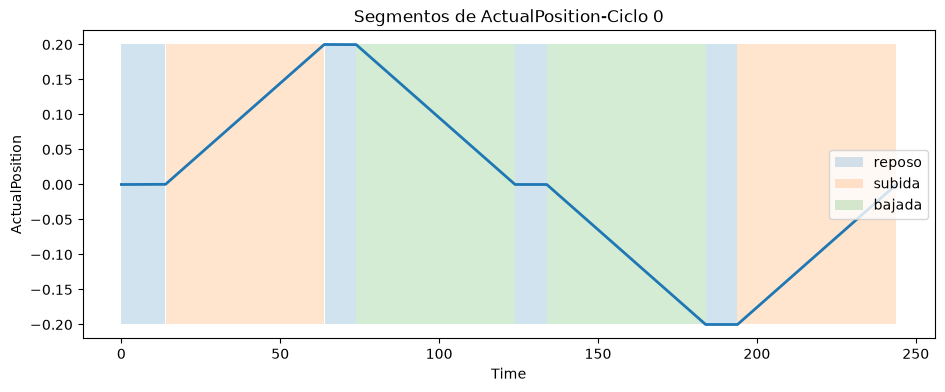

In [7]:
#grafica de un ciclo

c=int(df["cycle"].min())
dfc=df[df["cycle"]==c]
plt.figure(figsize=(11,4))
plt.plot(dfc["Time"],dfc["ActualPosition"],linewidth=2)

for val,label in [(0,"reposo"),(1,"subida"),(-1,"bajada")]:
    mask=dfc["sign"]==val
    plt.fill_between(dfc["Time"],dfc["ActualPosition"].min(),dfc["ActualPosition"].max(),where=mask,alpha=0.2,label=label)

plt.title(f"Segmentos de ActualPosition-Ciclo {c}")
plt.xlabel("Time")
plt.ylabel("ActualPosition")
plt.legend()
plt.show()

In [8]:
#quedarse con los tramos +1 y -1, segmentos en movimiento
seg_en_mov = seg[seg["sign"] != 0].copy()

In [9]:
levels_6 = np.array([0.004,0.008,0.016,0.032,0.064,0.128]) #las 6 velocidades preasignadas

dist = np.abs(seg_en_mov["v_rep"].to_numpy()[:,None] - levels_6[None,:]) #asignar velocidades a los segmentos sin redondear
indice = np.argmin(dist, axis=1) #donde la diferencia sea menor se le asigna una determinada velocidad de esas 6 a un segmento

seg_en_mov["velocity"] = levels_6[indice]


In [10]:
df = df.merge(seg_en_mov[["segment_id","velocity"]],on="segment_id",how="left")


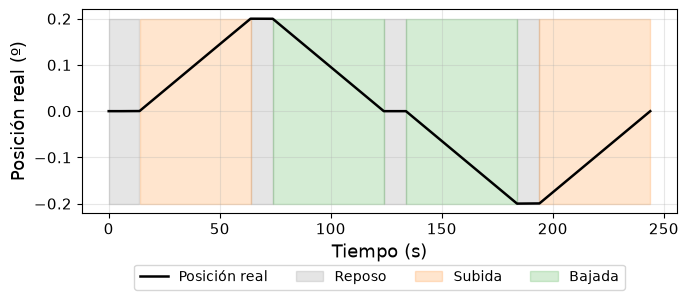

In [11]:
# --- Figura memoria: segmentación de un ciclo ---
c = int(df["cycle"].min())
dfc = df[df["cycle"] == c]

fig, ax = plt.subplots(figsize=(7,3.2))
ax.plot(dfc["Time"], dfc["ActualPosition"], color="black", linewidth=1.8, label="Posición real")
colores = {0: ("Reposo", "tab:gray"), 1: ("Subida", "tab:orange"), -1: ("Bajada", "tab:green")}
for val, (label, col) in colores.items():
    ax.fill_between(dfc["Time"], dfc["ActualPosition"].min(), dfc["ActualPosition"].max(),
                    where=dfc["sign"] == val, color=col, alpha=0.2, label=label)
ax.set_xlabel("Tiempo (s)", fontsize=13)
ax.set_ylabel("Posición real (º)", fontsize=13)
ax.tick_params(labelsize=11)
ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("segmentacion_ciclo.pdf", bbox_inches="tight")
plt.show()

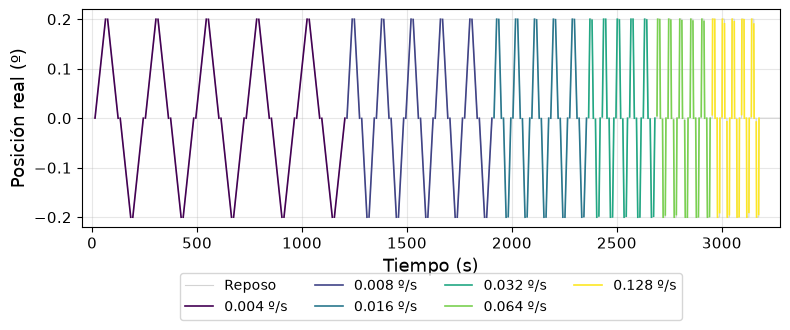

In [12]:
# --- Figura memoria: ensayo completo coloreado por velocidad asignada ---
fig, ax = plt.subplots(figsize=(8,3.5))
ax.plot(df["Time"], df["ActualPosition"], color="lightgray", linewidth=0.8, label="Reposo")
cmap = plt.get_cmap("viridis", len(levels_6))
for i, v in enumerate(levels_6):
    primero = True
    for sid, d in df[df["velocity"] == v].groupby("segment_id"):
        ax.plot(d["Time"], d["ActualPosition"], color=cmap(i), linewidth=1.2,
                label=f"{v} º/s" if primero else None)
        primero = False

t_fin = df.loc[df["velocity"].notna(), "Time"].max()
ax.set_xlim(-50, t_fin + 100)

ax.set_xlabel("Tiempo (s)", fontsize=13)
ax.set_ylabel("Posición real (º)", fontsize=13)
ax.tick_params(labelsize=11)
ax.legend(fontsize=10, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("segmentacion_velocidades.pdf", bbox_inches="tight")
plt.show()

In [13]:
#quitar los tramos que son 0 porque ahi no hay movimiento
df_mov = df[df["sign"] != 0].copy()
#agrupamos por ciclo y por segmento 
steps_summary = df_mov.groupby(["cycle","step"]).agg(sign=("sign","first"),velocity=("velocity","first"),segment_id=("segment_id","first"),
t_ini=("Time","min"),t_fin=("Time","max"),pos_ini=("SetPosition","first"),pos_fin=("SetPosition","last"),vel_mean=("ActualVelocity","mean"),vel_std=("ActualVelocity","std")).reset_index()


### Definición de métricas

Para evaluar cada velocidad se emplean las siguientes métricas, calculadas por tramo de movimiento (segmento):

- **Velocidad real**: pendiente de la posición real en el tramo central del segmento (régimen estacionario), en º/s.
- **Error de velocidad**: diferencia absoluta entre la velocidad real y la velocidad comandada, en º/s.
- **Duración**: tiempo total del segmento, en ms.
- **Rango recorrido**: distancia recorrida en el segmento, en º.

La siguiente tabla resume estas métricas agrupadas por velocidad comandada y sentido de movimiento (signo).

In [14]:
#cada segmento es un tramo completo de movimiento , ahora tenemos una fila por cada tramo de movimiento
segments_analysis = df_mov.groupby("segment_id").agg(

    cycle=("cycle","first"),
    step=("step","first"),
    
    sign=("sign","first"),
    velocity=("velocity","first"),
    
    t_ini=("Time","min"),
    t_fin=("Time","max"),
    
    duration=("Time", lambda x: x.max() - x.min()),
    
    pos_ini=("SetPosition","first"),
    pos_fin=("SetPosition","last"),
    
    vel_mean=("ActualVelocity","mean"),
    vel_std=("ActualVelocity","std"),
    vel_max=("ActualVelocity","max"),
    vel_min=("ActualVelocity","min"),

).reset_index()
segments_analysis


,segment_id,cycle,step,sign,velocity,t_ini,t_fin,duration,pos_ini,pos_fin,vel_mean,vel_std,vel_max,vel_min
0,2,0,1,1,0.004,13.9,63.9,50.0,0.000285,0.199999,0.003531,0.000523,0.004,0.000
1,4,0,3,-1,0.004,73.9,123.9,50.0,0.199818,0.000000,-0.004487,0.000650,0.000,-0.008
2,6,0,5,-1,0.004,133.9,183.9,50.0,-0.000109,-0.200001,-0.004495,0.000539,0.000,-0.005
3,8,0,7,1,0.004,193.9,243.9,50.0,-0.199964,0.000000,0.003475,0.000796,0.008,0.000
4,10,1,1,1,0.004,254.0,304.0,50.0,0.000333,0.199999,0.003499,0.000528,0.005,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,234,29,1,1,0.128,3129.2,3130.7,1.5,-0.189104,0.000000,0.121000,0.025605,0.128,0.025
118,236,29,3,1,0.128,3140.8,3142.4,1.6,0.004497,0.199999,0.119118,0.031315,0.128,-0.002
119,238,29,5,-1,0.128,3152.5,3154.0,1.5,0.189102,0.000000,-0.121813,0.025828,-0.025,-0.129
120,240,29,7,-1,0.128,3164.1,3165.6,1.5,-0.008849,-0.200001,-0.128438,0.000512,-0.128,-0.129


In [15]:
#resume todos los movimientos del mismo tipo
velocity_stats = segments_analysis.groupby(["velocity","sign"]).agg(

    n_segments=("segment_id","count"),
    
    mean_velocity=("vel_mean","mean"),
    std_velocity=("vel_mean","std"),
    
    mean_duration=("duration","mean"),
    
    mean_pos_ini=("pos_ini","mean"),
    mean_pos_fin=("pos_fin","mean")

).reset_index()

velocity_stats

,velocity,sign,n_segments,mean_velocity,std_velocity,mean_duration,mean_pos_ini,mean_pos_fin
0,0.004,-1,12,-0.003737,0.001746,41.666667,0.116459,-0.050001
1,0.004,1,10,0.003496,0.000018,50.000000,-0.099816,0.100000
2,0.008,-1,10,-0.008470,0.000033,25.000000,0.099521,-0.100001
3,0.008,1,10,0.007481,0.000039,25.000000,-0.099747,0.100000
4,0.016,-1,10,-0.016379,0.000046,12.500000,0.099180,-0.100001
5,0.016,1,10,0.015367,0.000058,12.500000,-0.099164,0.100000
6,0.032,-1,10,-0.032013,0.000331,6.240000,0.098503,-0.100001
7,0.032,1,10,0.031086,0.000180,6.240000,-0.097992,0.100000
8,0.064,-1,10,-0.062184,0.000954,3.130000,0.096946,-0.100001
9,0.064,1,10,0.061356,0.001006,3.140000,-0.097084,0.100000


In [16]:
pivot = velocity_stats.pivot(index="velocity",columns="sign",values="mean_velocity")

pivot

sign,-1,1
velocity,,
0.004,-0.003737,0.003496
0.008,-0.008470,0.007481
0.016,-0.016379,0.015367
0.032,-0.032013,0.031086
0.064,-0.062184,0.061356
0.128,-0.119645,0.119659


## c. Resultados - Seguimiento de velocidad

### Velocidad real vs. comandada

In [17]:
#error vs la velocidad comandada
segments_analysis["velocity_error"] = (segments_analysis["vel_mean"].abs() - segments_analysis["velocity"])


In [18]:
error_stats = segments_analysis.groupby(["velocity","sign"]).agg(mean_error=("velocity_error","mean"),std_error=("velocity_error","std")).reset_index()

### Linealidad

Se analiza si la velocidad real sigue linealmente a la velocidad comandada, y si el seguimiento de posición es lineal dentro de cada segmento.

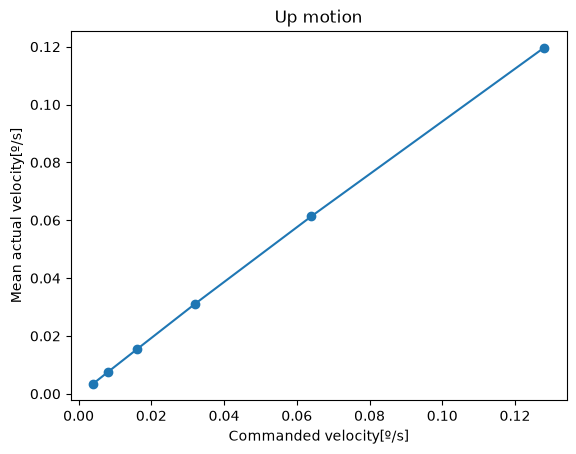

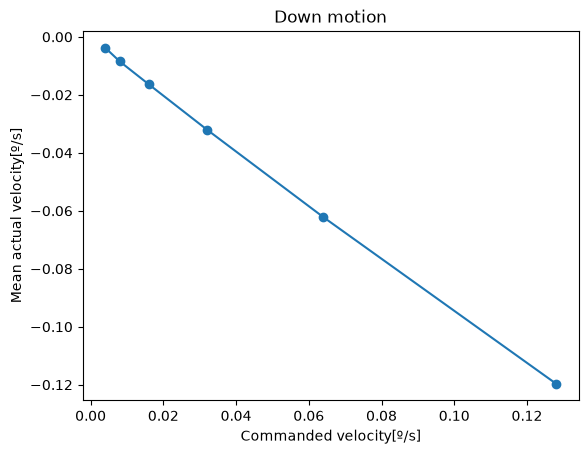

In [19]:

stats = segments_analysis.groupby(["velocity","sign"])["vel_mean"].mean().reset_index()

for s in [1, -1]:
    
    data = stats[stats["sign"] == s]
    
    plt.plot(data["velocity"], data["vel_mean"], "o-")
    
    if s == 1:
        label = "Up"
    else:
        label = "Down"
    
    plt.title(label + " motion")
    plt.xlabel("Commanded velocity[º/s]")
    plt.ylabel("Mean actual velocity[º/s]")
    
    plt.show()

Subida: m = 0.9366 ± 0.0075, b = 4.02e-04 ± 4.5e-04 º/s
Bajada: m = 0.9312 ± 0.0105, b = 1.29e-03 ± 6.3e-04 º/s


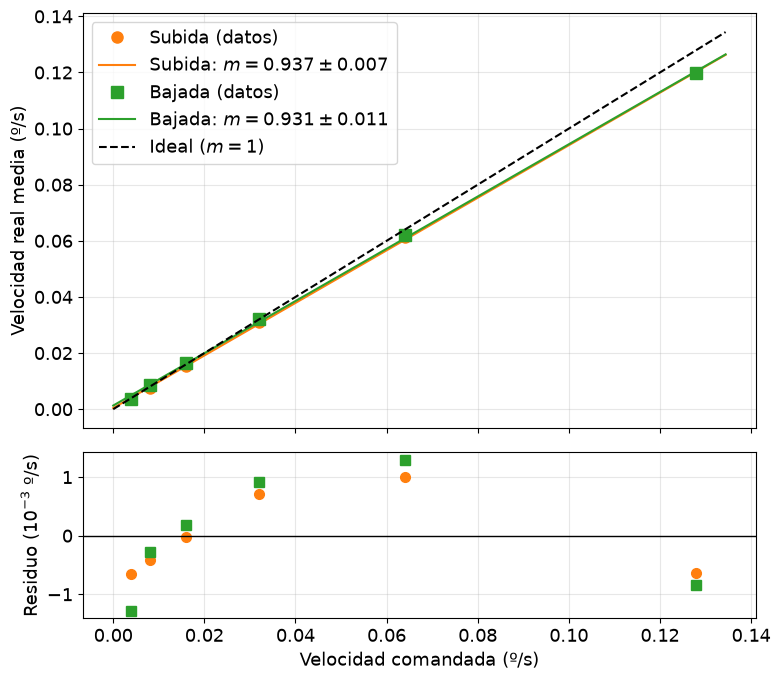

In [20]:
stats = segments_analysis.groupby(["velocity", "sign"])["vel_mean"].mean().reset_index()

sub = stats[stats["sign"] == 1].sort_values("velocity")
baj = stats[stats["sign"] == -1].sort_values("velocity")

v_cmd = sub["velocity"].values          # velocidades comandadas (º/s)
v_sub = sub["vel_mean"].values          # velocidad real media, subida
v_baj = baj["vel_mean"].abs().values    # velocidad real media, bajada (en valor absoluto)
plt.rcParams.update({'font.size': 13})

def ajuste(x, y):
    (m, b), cov = np.polyfit(x, y, 1, cov=True)
    sm, sb = np.sqrt(np.diag(cov))
    return m, b, sm, sb

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 7), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.2]})
xx = np.linspace(0, v_cmd.max()*1.05, 100)
for y, lab, c, mk in [(v_sub, 'Subida', 'tab:orange', 'o'),
                      (v_baj, 'Bajada', 'tab:green', 's')]:
    m, b, sm, sb = ajuste(v_cmd, y)
    print(f'{lab}: m = {m:.4f} ± {sm:.4f}, b = {b:.2e} ± {sb:.1e} º/s')
    ax.plot(v_cmd, y, mk, color=c, ms=8, label=f'{lab} (datos)')
    ax.plot(xx, m*xx + b, color=c, label=f'{lab}: $m = {m:.3f} \\pm {sm:.3f}$')
    axr.plot(v_cmd, (y - (m*v_cmd + b))*1e3, mk, color=c, ms=7)
ax.plot(xx, xx, 'k--', label='Ideal ($m = 1$)')
ax.set_ylabel('Velocidad real media (º/s)')
ax.legend(); ax.grid(alpha=.3)
axr.axhline(0, color='k', lw=1)
axr.set_ylabel(r'Residuo ($10^{-3}$ º/s)')
axr.set_xlabel('Velocidad comandada (º/s)'); axr.grid(alpha=.3)
fig.tight_layout()
fig.savefig('fig5_linealidad.pdf', bbox_inches='tight')

### Dispersión por velocidad

Dispersión (caja-bigotes) de la velocidad real medida para cada velocidad comandada, en º/s.

                mean    std  count   rel_%
velocity sign                             
0.004    -1   -0.263  1.746     12  -6.574
          1   -0.504  0.018     10 -12.605
0.008    -1    0.470  0.033     10   5.876
          1   -0.519  0.039     10  -6.489
0.016    -1    0.379  0.046     10   2.366
          1   -0.633  0.058     10  -3.953
0.032    -1    0.013  0.331     10   0.041
          1   -0.914  0.180     10  -2.857
0.064    -1   -1.816  0.954     10  -2.838
          1   -2.644  1.006     10  -4.131
0.128    -1   -8.355  4.477     10  -6.527
          1   -8.341  3.588     10  -6.516


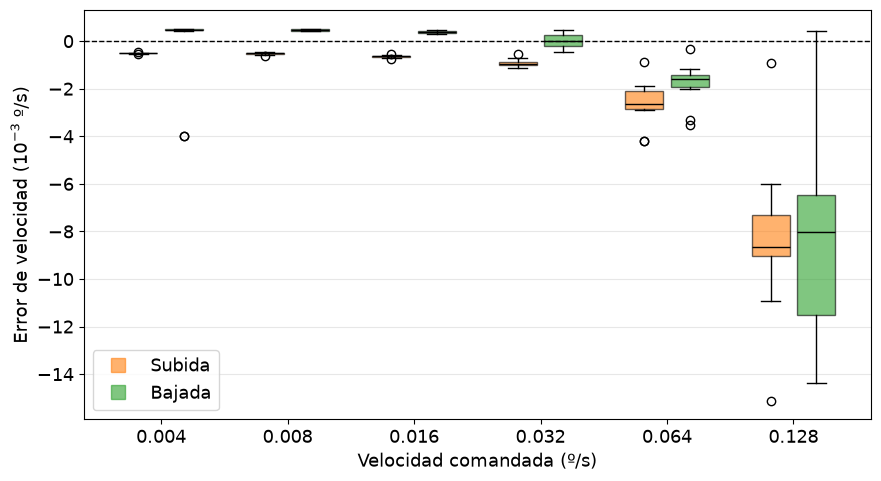

In [21]:
sa = segments_analysis.copy()
sa["err"] = sa["vel_mean"].abs() - sa["velocity"]
velocidades = sorted(sa["velocity"].unique())
pos = np.arange(len(velocidades))

fig, ax = plt.subplots(figsize=(9, 5))
for s, dx, color, label in [(1, -0.18, "tab:orange", "Subida"),
                            (-1, 0.18, "tab:green", "Bajada")]:
    datos = [sa[(sa["sign"] == s) & (sa["velocity"] == v)]["err"] * 1e3 for v in velocidades]
    bp = ax.boxplot(datos, positions=pos + dx, widths=0.3,
                    patch_artist=True, manage_ticks=False)
    for b in bp["boxes"]:
        b.set_facecolor(color); b.set_alpha(0.6)
    for m in bp["medians"]:
        m.set_color("k")
    ax.plot([], [], "s", color=color, alpha=0.6, ms=10, label=label)

ax.axhline(0, color="k", lw=1, ls="--")
ax.set_xticks(pos)
ax.set_xticklabels([str(v) for v in velocidades])
ax.set_xlabel("Velocidad comandada (º/s)")
ax.set_ylabel(r"Error de velocidad ($10^{-3}$ º/s)")
ax.legend(); ax.grid(alpha=.3, axis="y")
fig.tight_layout()
fig.savefig("fig6_dispersion.pdf", bbox_inches="tight")

res = sa.groupby(["velocity", "sign"])["err"].agg(["mean", "std", "count"])
res["mean"] *= 1e3
res["std"] *= 1e3
res["rel_%"] = res["mean"] / (res.index.get_level_values("velocity") * 1e3) * 100
print(res.round(3).to_string())

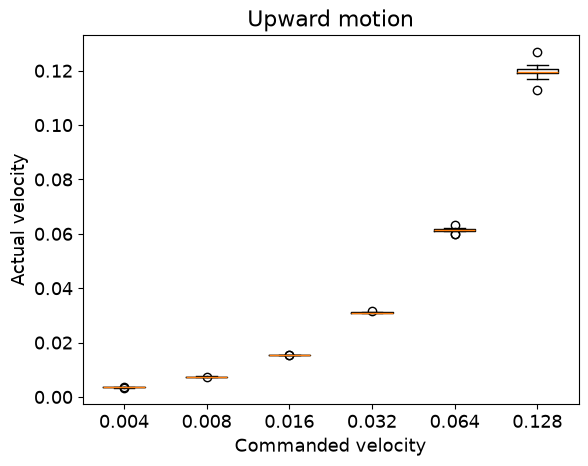

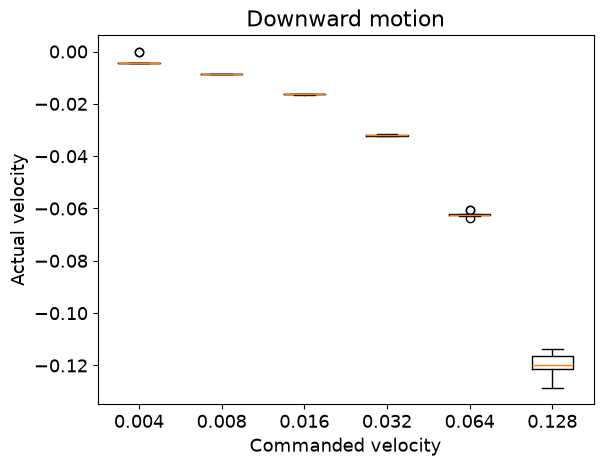

In [22]:
#cada caja es la dispersion de la velocidad real y cada grupo es 1 valor de la velocidad comandada

for s in [1, -1]:

    data = segments_analysis[segments_analysis["sign"] == s]
    
    velocities = sorted(data["velocity"].unique())
    
    box_data = [
        data[data["velocity"] == v]["vel_mean"]
        for v in velocities
    ]

    plt.figure()
    plt.boxplot(box_data, tick_labels=[str(v) for v in velocities])
    
    plt.xlabel("Commanded velocity")
    plt.ylabel("Actual velocity")
    
    if s == 1:
        plt.title("Upward motion")
    else:
        plt.title("Downward motion")
    
    plt.show()

### Determinación de la mejor velocidad 

In [23]:
# Resumen conjunto: error medio y dispersion (std) de velocidad real, por velocidad comandada
# (en º/s, unidades consistentes con el resto del analisis)
resumen_seguimiento = segments_analysis.groupby("velocity").agg(
    error_medio=("velocity_error", "mean"),
    error_std=("velocity_error", "std"),
    vel_real_std=("vel_mean", "std")
).round(6)
resumen_seguimiento["error_relativo_%"] = (resumen_seguimiento["error_medio"] / resumen_seguimiento.index * 100).round(2)
print(resumen_seguimiento.to_string())

          error_medio  error_std  vel_real_std  error_relativo_%
velocity                                                        
0.004       -0.000373   0.001269      0.003897             -9.32
0.008       -0.000025   0.000509      0.008183             -0.31
0.016       -0.000127   0.000521      0.016285             -0.79
0.032       -0.000451   0.000542      0.032370             -1.41
0.064       -0.002230   0.001044      0.063382             -3.48
0.128       -0.008348   0.003949      0.122824             -6.52


La velocidad v=0.008 da el valor menor para el error medio y el error relativo, la dispersión empieza a degradarse a partir de v=0.064.

## d. Resultados - Comportamiento dinámico

### Velocidad de referencia y repetibilidad

Se elige v=0.032 º/s como velocidad de referencia para el análisis dinámico detallado por ser una velocidad intermedia que evita tanto el ruido de las velocidades bajas como los efectos dinámicos más pronunciados de las velocidades altas.

In [24]:
#empezamos por una velocidad de en medio para evitar ruido
v_target = 0.032

segments_v = segments_analysis[segments_analysis["velocity"] == v_target].copy()

segments_up = segments_v[segments_v["sign"] == 1].copy()
segments_down = segments_v[segments_v["sign"] == -1].copy()

print("N up:", len(segments_up))
print("N down:", len(segments_down))

#buscamos duracion, posiciones y velocidad media para esos segmentos : tardan lo mismo? recorren lo mismo? la velocidad es consistente?
#repetibilidad, precision y consistencia. Lo hacemos con up y down

display(segments_up[["segment_id","duration","pos_ini","pos_fin","vel_mean"]].head())
display(segments_down[["segment_id","duration","pos_ini","pos_fin","vel_mean"]].head())

N up: 10
N down: 10


,segment_id,duration,pos_ini,pos_fin,vel_mean
61,123,6.2,0.001777,0.199999,0.031476
64,129,6.2,-0.197198,0.000000,0.031143
65,131,6.2,0.003121,0.199999,0.030937
68,137,6.3,-0.199054,0.000000,0.030984
69,139,6.3,0.001457,0.199999,0.031000


,segment_id,duration,pos_ini,pos_fin,vel_mean
62,125,6.2,0.197710,0.000000,-0.032143
63,127,6.2,-0.002547,-0.200001,-0.032000
66,133,6.3,0.199566,0.000000,-0.031547
67,135,6.3,-0.000691,-0.200001,-0.031984
70,141,6.2,0.198030,0.000000,-0.032476


In [25]:
#cuantificar .Crear rango de movimiento
segments_up["range_pos"]=segments_up["pos_fin"]-segments_up["pos_ini"]
segments_down["range_pos"]=segments_down["pos_fin"]-segments_down["pos_ini"]

In [26]:
#estadisticas de descripcion del tramo
display(segments_up[["duration","range_pos","vel_mean"]].describe())
display(segments_down[["duration","range_pos","vel_mean"]].describe())

,duration,range_pos,vel_mean
count,10.00000,10.000000,10.000000
mean,6.24000,0.197992,0.031086
std,0.05164,0.000853,0.000180
min,6.20000,0.196878,0.030891
25%,6.20000,0.197278,0.030984
50%,6.20000,0.197934,0.031024
75%,6.30000,0.198638,0.031131
max,6.30000,0.199182,0.031476


,duration,range_pos,vel_mean
count,10.00000,10.000000,10.000000
mean,6.24000,-0.198504,-0.032013
std,0.05164,0.000884,0.000331
min,6.20000,-0.199694,-0.032476
25%,6.20000,-0.199406,-0.032250
50%,6.20000,-0.198094,-0.032008
75%,6.30000,-0.197806,-0.031785
max,6.30000,-0.197454,-0.031547


In [27]:
#tabla resumen con las estadisticas 
summary = pd.DataFrame({
    "up_mean": segments_up[["duration", "range_pos", "vel_mean"]].mean(),
    "up_std": segments_up[["duration", "range_pos", "vel_mean"]].std(),
    "down_mean": segments_down[["duration", "range_pos", "vel_mean"]].mean(),
    "down_std": segments_down[["duration", "range_pos", "vel_mean"]].std(),
})

summary

,up_mean,up_std,down_mean,down_std
duration,6.240000,0.051640,6.240000,0.051640
range_pos,0.197992,0.000853,-0.198504,0.000884
vel_mean,0.031086,0.000180,-0.032013,0.000331


<Figure size 600x400 with 0 Axes>

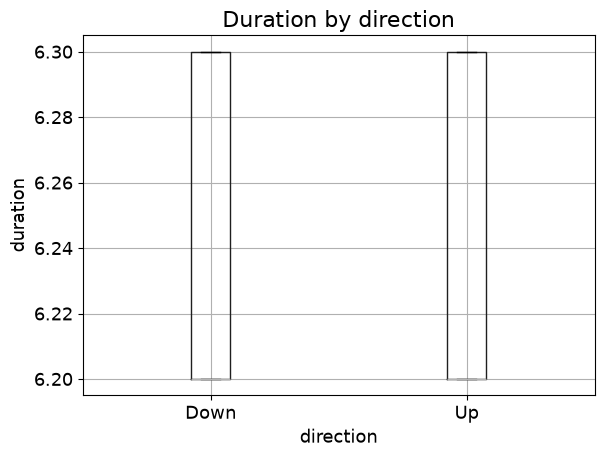

In [28]:
#graficar lo que estamos evaluando
#1.duration
plot_df = pd.concat([
    segments_up[["duration"]].assign(direction="Up"),
    segments_down[["duration"]].assign(direction="Down")
])

plt.figure(figsize=(6,4))
plot_df.boxplot(column="duration", by="direction")
plt.suptitle("")
plt.title("Duration by direction")
plt.ylabel("duration")
plt.show()
#practicamente duran lo mismo independientemente de subir o bajar

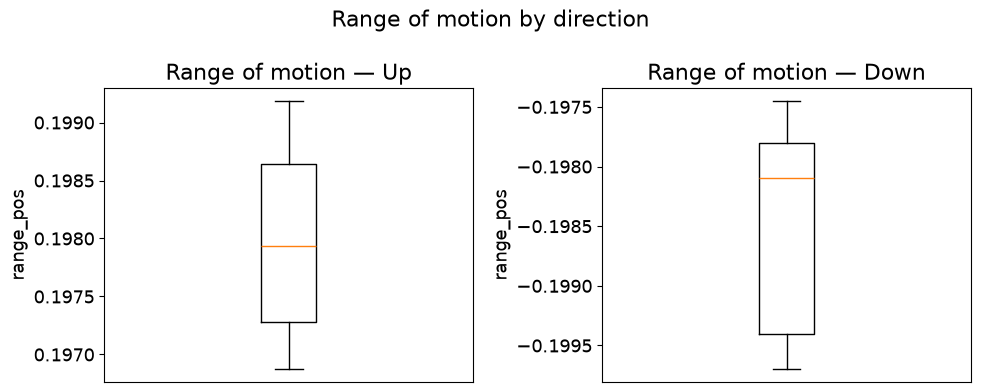

In [29]:
#2.rango de movimiento para ver si llega a donde se supone que debe llegar CAMBIAR

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (direction, seg) in zip(axes, [("Up", segments_up), ("Down", segments_down)]):
    ax.boxplot(seg["range_pos"].dropna())
    ax.set_title(f"Range of motion — {direction}")
    ax.set_ylabel("range_pos")
    ax.set_xticks([])

plt.suptitle("Range of motion by direction")
plt.tight_layout()
plt.show()
#se ve precision espacial muy alta porque llega siempre al mismo punto y no se ve desviacion relevante

### Clasificación de segmentos por grupo (v=0.032)

Se clasifican los segmentos en dos grupos según su posición de origen usando K-Means, para analizar si el comportamiento dinámico depende de la zona del recorrido. Se repite para ambos sentidos de movimiento (subida y bajada).

In [30]:
#para comparar segmentos, 2 tipos , los que van desde 0 a 0.2 y los que van desde -0.2 a 0

from sklearn.cluster import KMeans

v_target = 0.032
s_target = 1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

# Agrupar por pos_ini sin threshold manual
km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

# Etiquetar por el centro real (el grupo 0 puede ser cualquiera)
centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

print(segs[["segment_id", "pos_ini", "pos_fin", "grupo"]].to_string())

    segment_id   pos_ini   pos_fin          grupo
61         123  0.001777  0.199999  centro→arriba
64         129 -0.197198  0.000000    bajo→centro
65         131  0.003121  0.199999  centro→arriba
68         137 -0.199054  0.000000    bajo→centro
69         139  0.001457  0.199999  centro→arriba
72         145 -0.197518  0.000000    bajo→centro
73         147  0.002993  0.199999  centro→arriba
76         153 -0.199182  0.000000    bajo→centro
77         155  0.001329  0.199999  centro→arriba
80         161 -0.197646  0.000000    bajo→centro


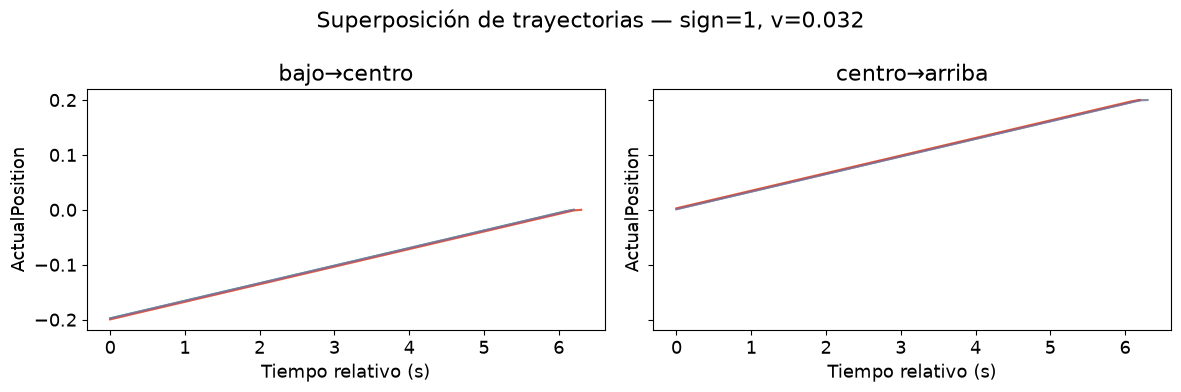

In [31]:
#los dos grupos con tiempo relativo, empieza en 0 en cada segmento
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    
    grupo_segs = segs[segs["grupo"] == grupo_nombre]
    
    for _, row in grupo_segs.iterrows():
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()
        t_rel = seg_data["Time"] - seg_data["Time"].iloc[0]
        ax.plot(t_rel, seg_data["ActualPosition"], alpha=0.6, linewidth=1.5)
    
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo (s)")
    ax.set_ylabel("ActualPosition")

plt.suptitle(f"Superposición de trayectorias — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()
#repetibilidad alta: todos los ciclos del mismo grupo se superponen porque las lineas son casi indistinguibles
#consistencia porque para la misma v y direccion se recorre el camino de la misma forma, la curva que se ve debe
#ser por el arranque del sistema
#empiezan en dos posiciones absolutas distintas (-0.2 vs 0) porque son dos tramos diferentes del recorrido

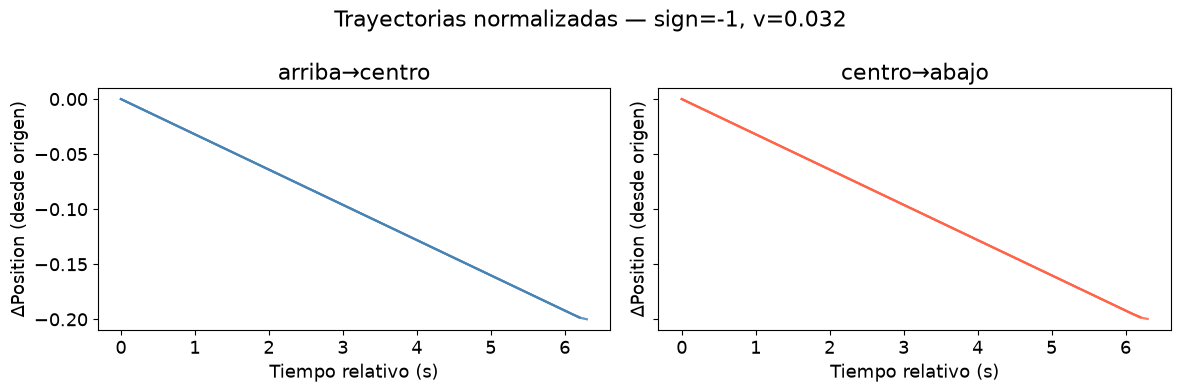

In [32]:


v_target = 0.032
s_target = -1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmax(): "arriba→centro", centros.idxmin(): "centro→abajo"}
segs["grupo"] = segs["grupo"].map(mapa)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

colores = {"arriba→centro": "steelblue", "centro→abajo": "tomato"}

for ax, (grupo_nombre, color) in zip(axes, colores.items()):
    
    grupo_segs = segs[segs["grupo"] == grupo_nombre]
    
    for _, row in grupo_segs.iterrows():
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()
        t_rel = seg_data["Time"] - seg_data["Time"].iloc[0]
        pos_norm = seg_data["ActualPosition"] - seg_data["ActualPosition"].iloc[0]
        ax.plot(t_rel, pos_norm, alpha=0.6, linewidth=1.5, color=color)
    
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo (s)")
    ax.set_ylabel("ΔPosition (desde origen)")

plt.suptitle(f"Trayectorias normalizadas — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

### Arranque

Al analizar una ventana temporal alrededor del inicio de cada segmento, se observa que el sistema permanece en reposo antes de t=0 y comienza el movimiento a partir de ese instante. No se detecta una fase de aceleración apreciable en la posición.

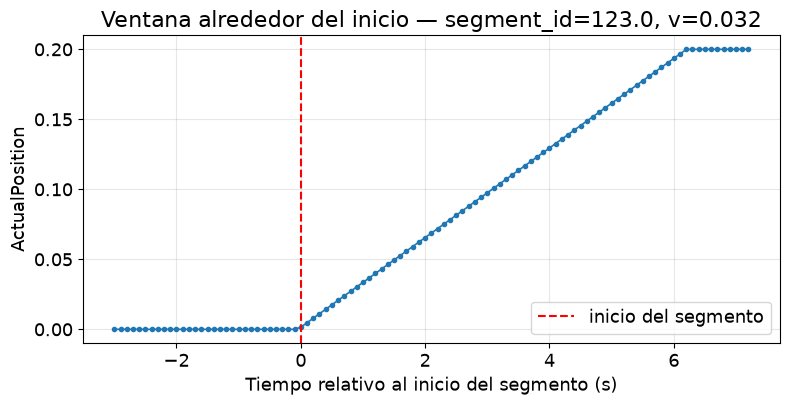

In [33]:
# VER QUÉ PASA JUSTO ANTES DEL INICIO DEL SEGMENTO
v_target = 0.032
s_target = 1

# cogemos el primer segmento de ese tipo
row = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].iloc[0]

seg_id = row["segment_id"]

# índices del segmento en df
idx_seg = df.index[df["segment_id"] == seg_id]
i0 = idx_seg.min()
i1 = idx_seg.max()

# coger puntos antes y después
n_pre = 30   # puntos antes del inicio
n_post = 10  # puntos después del final, por si acaso

i_start = max(df.index.min(), i0 - n_pre)
i_end   = min(df.index.max(), i1 + n_post)

tmp = df.loc[i_start:i_end].copy()

# tiempo relativo respecto al inicio del segmento
t_rel = tmp["Time"].values - df.loc[i0, "Time"]

plt.figure(figsize=(9, 4))
plt.plot(t_rel, tmp["ActualPosition"].values, marker="o", markersize=3, linewidth=1.2)

plt.axvline(0, color="red", linestyle="--", label="inicio del segmento")
plt.xlabel("Tiempo relativo al inicio del segmento (s)")
plt.ylabel("ActualPosition")
plt.title(f"Ventana alrededor del inicio — segment_id={seg_id}, v={v_target}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

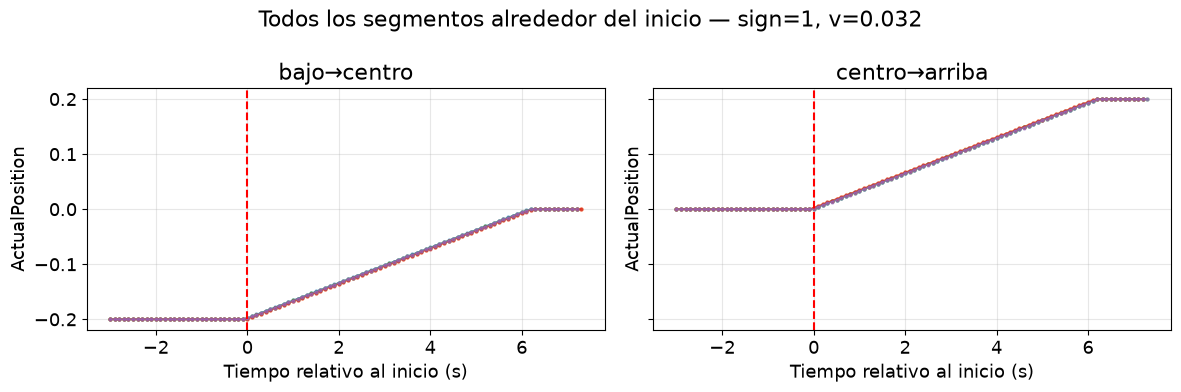

In [34]:
# TODOS LOS SEGMENTOS: ventana alrededor del inicio, separados por grupo
v_target = 0.032
s_target = 1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

n_pre = 30
n_post = 10

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    grupo_segs = segs[segs["grupo"] == grupo_nombre]

    for _, row in grupo_segs.iterrows():
        seg_id = row["segment_id"]

        idx_seg = df.index[df["segment_id"] == seg_id]
        i0 = idx_seg.min()
        i1 = idx_seg.max()

        i_start = max(df.index.min(), i0 - n_pre)
        i_end   = min(df.index.max(), i1 + n_post)

        tmp = df.loc[i_start:i_end].copy()
        t_rel = tmp["Time"].values - df.loc[i0, "Time"]

        ax.plot(t_rel, tmp["ActualPosition"].values,
                marker="o", markersize=2, linewidth=1, alpha=0.6)

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo al inicio (s)")
    ax.set_ylabel("ActualPosition")
    ax.grid(alpha=0.3)

plt.suptitle(f"Todos los segmentos alrededor del inicio — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

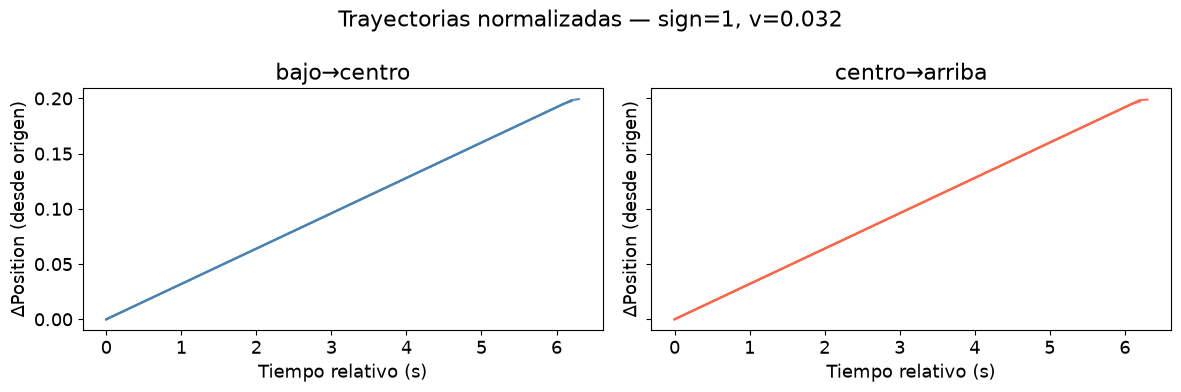

In [35]:
#ahora resto la posicion inicial para que ambos grupos empiecen en 0 y se puedan poner en la misma grafica para ver 
#si el comportamiento dinamico es = da igual de donde parta

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

colores = {"bajo→centro": "steelblue", "centro→arriba": "tomato"}

for ax, (grupo_nombre, color) in zip(axes, colores.items()):
    
    grupo_segs = segs[segs["grupo"] == grupo_nombre]
    
    for _, row in grupo_segs.iterrows():
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()
        t_rel = seg_data["Time"] - seg_data["Time"].iloc[0]
        pos_norm = seg_data["ActualPosition"] - seg_data["ActualPosition"].iloc[0]
        ax.plot(t_rel, pos_norm, alpha=0.6, linewidth=1.5, color=color)
    
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo (s)")
    ax.set_ylabel("ΔPosition (desde origen)")

plt.suptitle(f"Trayectorias normalizadas — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

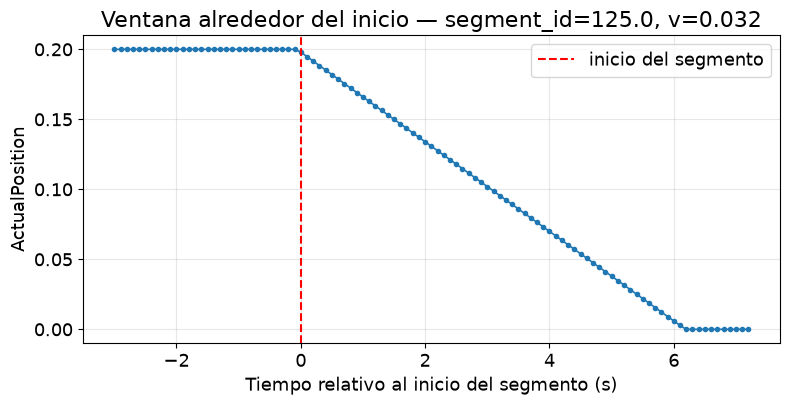

In [36]:
# VER QUÉ PASA JUSTO ANTES DEL INICIO DEL SEGMENTO
v_target = 0.032
s_target = -1

# cogemos el primer segmento de ese tipo
row = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].iloc[0]

seg_id = row["segment_id"]

# índices del segmento en df
idx_seg = df.index[df["segment_id"] == seg_id]
i0 = idx_seg.min()
i1 = idx_seg.max()

# coger puntos antes y después
n_pre = 30   # puntos antes del inicio
n_post = 10  # puntos después del final, por si acaso

i_start = max(df.index.min(), i0 - n_pre)
i_end   = min(df.index.max(), i1 + n_post)

tmp = df.loc[i_start:i_end].copy()

# tiempo relativo respecto al inicio del segmento
t_rel = tmp["Time"].values - df.loc[i0, "Time"]

plt.figure(figsize=(9, 4))
plt.plot(t_rel, tmp["ActualPosition"].values, marker="o", markersize=3, linewidth=1.2)

plt.axvline(0, color="red", linestyle="--", label="inicio del segmento")
plt.xlabel("Tiempo relativo al inicio del segmento (s)")
plt.ylabel("ActualPosition")
plt.title(f"Ventana alrededor del inicio — segment_id={seg_id}, v={v_target}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

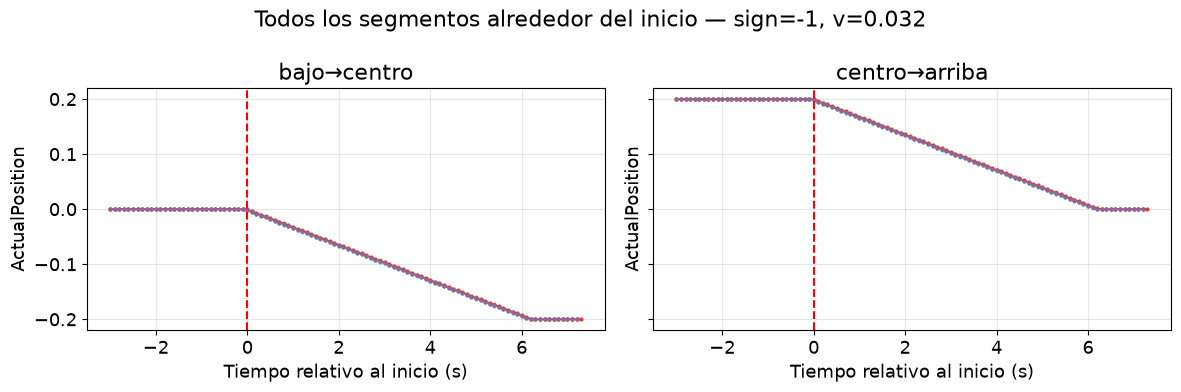

In [37]:
# TODOS LOS SEGMENTOS: ventana alrededor del inicio, separados por grupo
v_target = 0.032
s_target = -1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

n_pre = 30
n_post = 10

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    grupo_segs = segs[segs["grupo"] == grupo_nombre]

    for _, row in grupo_segs.iterrows():
        seg_id = row["segment_id"]

        idx_seg = df.index[df["segment_id"] == seg_id]
        i0 = idx_seg.min()
        i1 = idx_seg.max()

        i_start = max(df.index.min(), i0 - n_pre)
        i_end   = min(df.index.max(), i1 + n_post)

        tmp = df.loc[i_start:i_end].copy()
        t_rel = tmp["Time"].values - df.loc[i0, "Time"]

        ax.plot(t_rel, tmp["ActualPosition"].values,
                marker="o", markersize=2, linewidth=1, alpha=0.6)

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo al inicio (s)")
    ax.set_ylabel("ActualPosition")
    ax.grid(alpha=0.3)

plt.suptitle(f"Todos los segmentos alrededor del inicio — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

### Frenada

En la fase final del movimiento se observa una desviación respecto al comportamiento lineal, caracterizada por una reducción de la pendiente, consistente con una fase de desaceleración antes de alcanzar la posición objetivo.

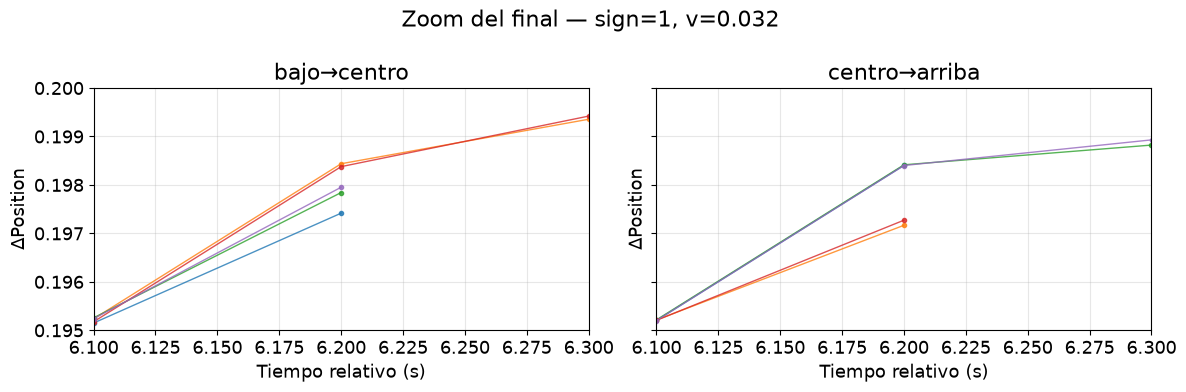

In [38]:
# ZOOM DEL FINAL DEL MOVIMIENTO

v_target = 0.032
s_target = 1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

t_tail = 0.5   # últimos 0.5 segundos

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    grupo_segs = segs[segs["grupo"] == grupo_nombre]

    for _, row in grupo_segs.iterrows():
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()

        t_rel = seg_data["Time"].values - seg_data["Time"].iloc[0]
        pos_norm = seg_data["ActualPosition"].values - seg_data["ActualPosition"].iloc[0]

        t_final = t_rel[-1]
        mask = t_rel >= (t_final - t_tail)

        ax.plot(t_rel[mask], pos_norm[mask],
                marker="o", markersize=3, alpha=0.8, linewidth=1)

    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo (s)")
    ax.set_ylabel("ΔPosition")
    ax.grid(alpha=0.3)
    ax.set_xlim(6.1, 6.3)
    ax.set_ylim(0.1950,0.2)


plt.suptitle(f"Zoom del final — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

In [39]:

v_target = 0.032
s_target = 1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

resultados_frenada = []

for _, row in segs.iterrows():
    seg_data = df[df["segment_id"] == row["segment_id"]].copy()

    t_rel = seg_data["Time"].values - seg_data["Time"].iloc[0]
    x_rel = seg_data["ActualPosition"].values - seg_data["ActualPosition"].iloc[0]

    # quitamos puntos de reposo final si los hubiera usando solo hasta el último cambio
    dx = np.diff(x_rel)
    idx_mov = np.where(np.abs(dx) > 0)[0]

    if len(idx_mov) < 4:
        continue

    last_move_idx = idx_mov[-1] + 1
    t_mov = t_rel[:last_move_idx + 1]
    x_mov = x_rel[:last_move_idx + 1]

    # zona central: del 30% al 70% del movimiento
    n = len(t_mov)
    i1 = int(0.30 * n)
    i2 = int(0.70 * n)

    # zona final: últimos 3-4 puntos con cambio
    j1 = max(0, n - 4)

    X_central = t_mov[i1:i2].reshape(-1, 1)
    y_central = x_mov[i1:i2]

    X_final = t_mov[j1:].reshape(-1, 1)
    y_final = x_mov[j1:]

    if len(X_central) < 2 or len(X_final) < 2:
        continue

    reg_c = LinearRegression().fit(X_central, y_central)
    reg_f = LinearRegression().fit(X_final, y_final)

    slope_central = reg_c.coef_[0]
    slope_final = reg_f.coef_[0]

    ratio = abs(slope_final) / abs(slope_central) if slope_central != 0 else np.nan

    resultados_frenada.append({
        "segment_id": row["segment_id"],
        "grupo": row["grupo"],
        "slope_central": slope_central,
        "slope_final": slope_final,
        "ratio_final_central": ratio
    })

frenada_df = pd.DataFrame(resultados_frenada)
display(frenada_df)
display(frenada_df.groupby("grupo")[["slope_central", "slope_final", "ratio_final_central"]].agg(["mean", "std", "count"]))

,segment_id,grupo,slope_central,slope_final,ratio_final_central
0,123,centro→arriba,0.032000,0.032003,1.000093
1,129,bajo→centro,0.032001,0.029187,0.912070
2,131,centro→arriba,0.032002,0.028273,0.883488
3,137,bajo→centro,0.032001,0.025170,0.786548
4,139,centro→arriba,0.032001,0.023621,0.738126
5,145,bajo→centro,0.032000,0.030156,0.942363
6,147,centro→arriba,0.032001,0.028595,0.893577
7,153,bajo→centro,0.032001,0.025536,0.797986
8,155,centro→arriba,0.032001,0.023995,0.749819
9,161,bajo→centro,0.032000,0.030535,0.954214


slope_central                     slope_final                  \
                       mean           std count        mean       std count   
grupo                                                                         
bajo→centro        0.032001  2.466635e-07     5    0.028117  0.002574     5   
centro→arriba      0.032001  6.067634e-07     5    0.027297  0.003507     5   

              ratio_final_central                  
                             mean       std count  
grupo                                              
bajo→centro              0.878636  0.080429     5  
centro→arriba            0.853021  0.109607     5

La pendiente en régimen central reproduce con  la velocidad impuesta, validando el comportamiento del sistema en condiciones estacionarias.

En la fase final, la pendiente disminuye de forma sistemática, alcanzando aproximadamente el 85–88% de la velocidad. Esta reducción corresponde a una desaceleración controlada del orden del 12–15%.

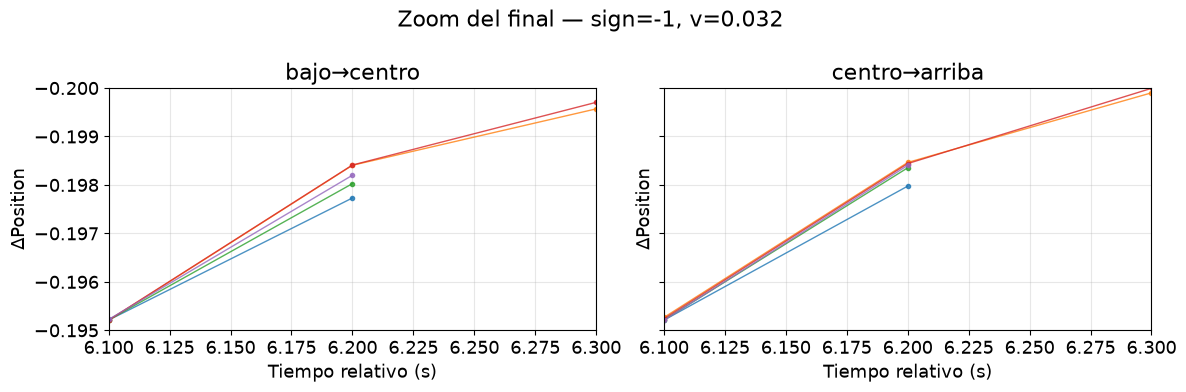

In [40]:
# ZOOM DEL FINAL DEL MOVIMIENTO

v_target = 0.032
s_target = -1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

t_tail = 0.5   # últimos 0.5 segundos

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    grupo_segs = segs[segs["grupo"] == grupo_nombre]

    for _, row in grupo_segs.iterrows():
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()

        t_rel = seg_data["Time"].values - seg_data["Time"].iloc[0]
        pos_norm = seg_data["ActualPosition"].values - seg_data["ActualPosition"].iloc[0]

        t_final = t_rel[-1]
        mask = t_rel >= (t_final - t_tail)

        ax.plot(t_rel[mask], pos_norm[mask],
                marker="o", markersize=3, alpha=0.8, linewidth=1)

    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo relativo (s)")
    ax.set_ylabel("ΔPosition")
    ax.grid(alpha=0.3)
    ax.set_ylim(-0.1950,-0.2)
    ax.set_xlim(6.1,6.3)
   


plt.suptitle(f"Zoom del final — sign={s_target}, v={v_target}")
plt.tight_layout()
plt.show()

In [41]:
# CUANTIFICAR FRENADA: pendiente central vs pendiente final
v_target = 0.032
s_target = -1

segs = segments_analysis[
    (segments_analysis["velocity"] == v_target) &
    (segments_analysis["sign"] == s_target)
].copy()

from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

km = KMeans(n_clusters=2, random_state=0)
segs["grupo"] = km.fit_predict(segs[["pos_ini"]])

centros = segs.groupby("grupo")["pos_ini"].mean()
mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
segs["grupo"] = segs["grupo"].map(mapa)

resultados_frenada = []

for _, row in segs.iterrows():
    seg_data = df[df["segment_id"] == row["segment_id"]].copy()

    t_rel = seg_data["Time"].values - seg_data["Time"].iloc[0]
    x_rel = seg_data["ActualPosition"].values - seg_data["ActualPosition"].iloc[0]

    # quitamos puntos de reposo final si los hubiera usando solo hasta el último cambio
    dx = np.diff(x_rel)
    idx_mov = np.where(np.abs(dx) > 0)[0]

    if len(idx_mov) < 4:
        continue

    last_move_idx = idx_mov[-1] + 1
    t_mov = t_rel[:last_move_idx + 1]
    x_mov = x_rel[:last_move_idx + 1]

    # zona central: del 30% al 70% del movimiento
    n = len(t_mov)
    i1 = int(0.30 * n)
    i2 = int(0.70 * n)

    # zona final: últimos 3-4 puntos con cambio
    j1 = max(0, n - 4)

    X_central = t_mov[i1:i2].reshape(-1, 1)
    y_central = x_mov[i1:i2]

    X_final = t_mov[j1:].reshape(-1, 1)
    y_final = x_mov[j1:]

    if len(X_central) < 2 or len(X_final) < 2:
        continue

    reg_c = LinearRegression().fit(X_central, y_central)
    reg_f = LinearRegression().fit(X_final, y_final)

    slope_central = reg_c.coef_[0]
    slope_final = reg_f.coef_[0]

    ratio = abs(slope_final) / abs(slope_central) if slope_central != 0 else np.nan

    resultados_frenada.append({
        "segment_id": row["segment_id"],
        "grupo": row["grupo"],
        "slope_central": slope_central,
        "slope_final": slope_final,
        "ratio_final_central": ratio
    })

frenada_df = pd.DataFrame(resultados_frenada)
display(frenada_df)
display(frenada_df.groupby("grupo")[["slope_central", "slope_final", "ratio_final_central"]].agg(["mean", "std", "count"]))

,segment_id,grupo,slope_central,slope_final,ratio_final_central
0,125,centro→arriba,-0.032000,-0.030685,0.958893
1,127,bajo→centro,-0.032000,-0.029947,0.935840
2,133,centro→arriba,-0.032000,-0.026691,0.834090
3,135,bajo→centro,-0.032000,-0.025891,0.809100
4,141,centro→arriba,-0.032002,-0.031829,0.994598
5,143,bajo→centro,-0.032000,-0.030846,0.963947
6,149,centro→arriba,-0.032001,-0.027063,0.845695
7,151,bajo→centro,-0.032000,-0.026289,0.821527
8,157,centro→arriba,-0.032001,-0.031999,0.999932
9,159,bajo→centro,-0.032000,-0.031323,0.978854


slope_central                     slope_final                  \
                       mean           std count        mean       std count   
grupo                                                                         
bajo→centro       -0.032000  2.544782e-07     5   -0.028859  0.002580     5   
centro→arriba     -0.032001  6.647220e-07     5   -0.029653  0.002588     5   

              ratio_final_central                  
                             mean       std count  
grupo                                              
bajo→centro              0.901854  0.080615     5  
centro→arriba            0.926642  0.080852     5

En el caso de movimientos con signo negativo, la pendiente en régimen central coincide con la velocidad impuesta


En la fase final del movimiento se observa una ligera reducción de la pendiente. El cociente entre la pendiente final y la central toma valores medios en torno a 0.90–0.93, lo que indica una disminución de la velocidad del orden del 7–10% antes de alcanzar la posición objetivo.

Esta reducción es moderada y sugiere una desaceleración suave en la fase final.

En el caso de movimientos con  signo positivo, la pendiente en régimen central coincide con la velocidad impuesta


Sin embargo, en la fase final del movimiento se observa una reducción más acusada de la pendiente. El cociente entre la pendiente final y la central toma valores medios en torno a 0.85–0.88, lo que indica una disminución de la velocidad del orden del 12–15% antes de alcanzar la posición objetivo.

Esta reducción más intensa refleja una desaceleración más pronunciada en comparación con el caso de signo negativo.

### Comparación entre velocidades — Arranque y Frenada

Se extiende el análisis dinámico a las 6 velocidades comandadas, normalizando tiempo y posición para poder comparar trayectorias de distinta duración en la misma escala.

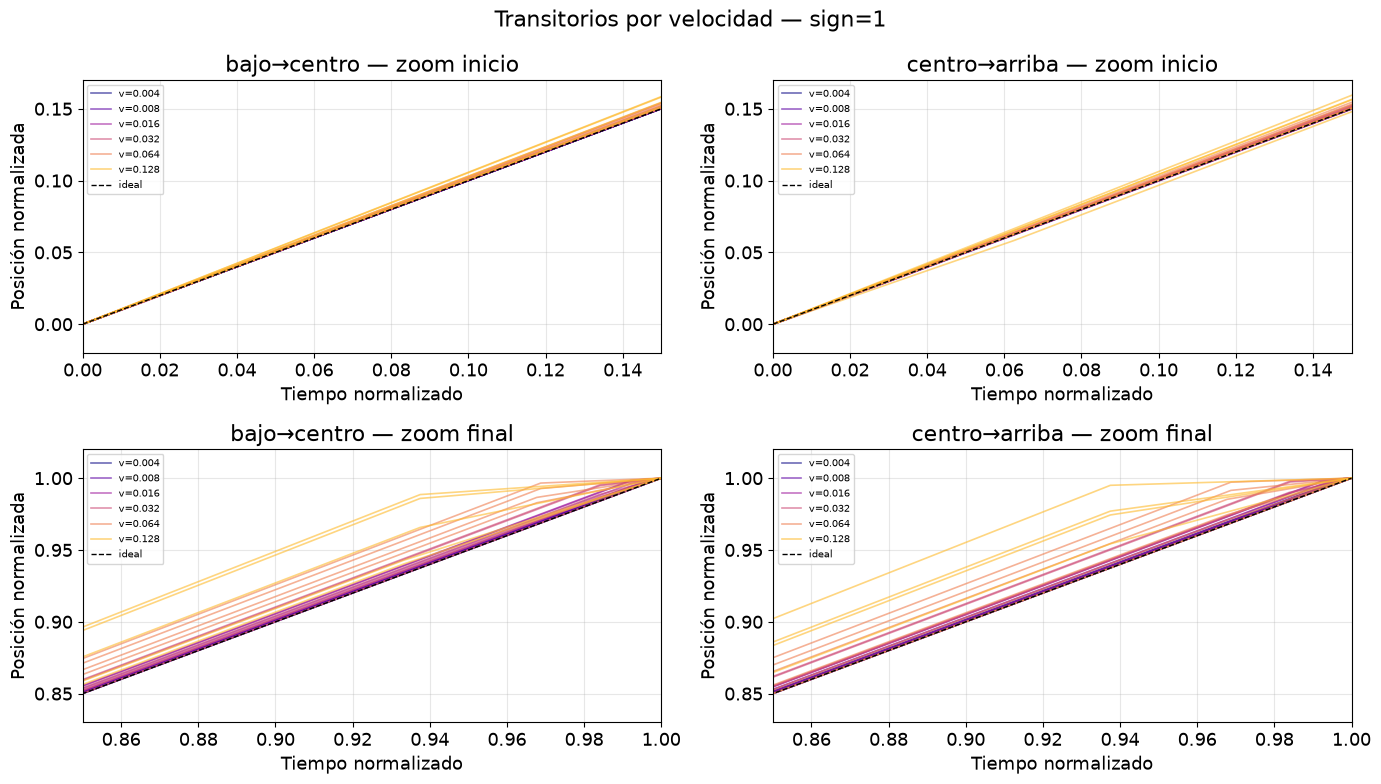

In [42]:
velocidades = sorted(segments_analysis["velocity"].unique())
colores_vel = plt.cm.plasma(np.linspace(0, 0.85, len(velocidades)))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

zooms = {"inicio": (0.0, 0.15), "final": (0.85, 1.0)}

for col, grupo_nombre in enumerate(["bajo→centro", "centro→arriba"]):
    for row, (zona, (t_min, t_max)) in enumerate(zooms.items()):
        ax = axes[row, col]
        
        for v, color in zip(velocidades, colores_vel):
            segs = segments_analysis[
                (segments_analysis["velocity"] == v) &
                (segments_analysis["sign"] == 1)
            ].copy()
            if len(segs) == 0:
                continue
            
            km = KMeans(n_clusters=2, random_state=0)
            segs["grupo"] = km.fit_predict(segs[["pos_ini"]])
            centros = segs.groupby("grupo")["pos_ini"].mean()
            mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
            segs["grupo"] = segs["grupo"].map(mapa)
            grupo_segs = segs[segs["grupo"] == grupo_nombre]
            
            for i, (_, row_s) in enumerate(grupo_segs.iterrows()):
                seg_data = df[df["segment_id"] == row_s["segment_id"]].copy()
                t = seg_data["Time"].values - seg_data["Time"].values[0]
                t_norm = t / t[-1]
                pos = seg_data["ActualPosition"].values - seg_data["ActualPosition"].values[0]
                pos_norm = pos / pos[-1] if pos[-1] != 0 else pos
                label = f"v={v}" if i == 0 else None
                ax.plot(t_norm, pos_norm, alpha=0.6, linewidth=1.2, color=color, label=label)
        
        ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="ideal")
        ax.set_xlim(t_min, t_max)
        ax.set_ylim(t_min - 0.02, t_max + 0.02)
        ax.set_title(f"{grupo_nombre} — zoom {zona}")
        ax.set_xlabel("Tiempo normalizado")
        ax.set_ylabel("Posición normalizada")
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)

plt.suptitle("Transitorios por velocidad — sign=1")
plt.tight_layout()
plt.show()




En el zoom inicio, el tiempo lo hemos normalizado de 0 a 0.15 para ver lo que pasaba cerca del 0. Todas las velocidades siguen practicamente la linea ideal no se aprecia apenas ninguna desviación en el movimiento de arranque. (puede ser porque sea inferior a la resolucion temporal que tenemos).

En el zoom del final, donde el tiempo va de 0.85 a 1.00, se ve que todas las velocidades se separan de la línea ideal antes de llegar al destino, la posición real va por debajo de la ideal (fase desaceleracion). El patrón con respecto a las distintas velocidades es: las velocidades más altas (0.064 y 0.128) se desvían más y antes, las más bajas se mantienen más cerca de la ideal. Explicación física simple, a mayor velocidad más tiempo y espacio necesitaría el stma para frenar.

#### Residuos respecto a la trayectoria ideal

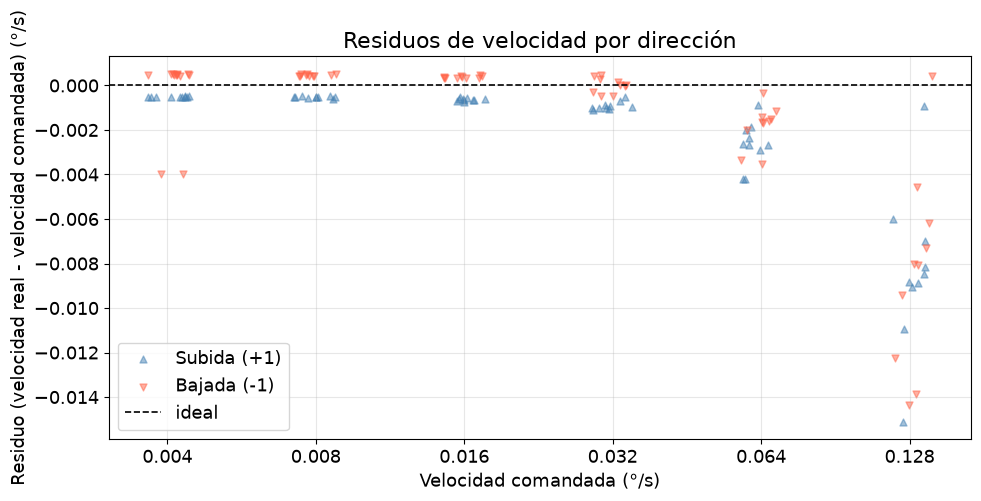

In [43]:
velocidades = sorted(segments_analysis["velocity"].unique())
vel_to_x = {v: i for i, v in enumerate(velocidades)}

fig, ax = plt.subplots(figsize=(10, 5))

for s, marker, color, label in [(1, "^", "steelblue", "Subida (+1)"),
                                  (-1, "v", "tomato", "Bajada (-1)")]:
    data = segments_analysis[segments_analysis["sign"] == s].copy()
    residuos = data["vel_mean"].abs() - data["velocity"]
    x_pos = data["velocity"].map(vel_to_x)
    jitter = np.random.uniform(-0.15, 0.15, size=len(data))
    
    ax.scatter(x_pos + jitter, residuos,
               alpha=0.5, s=25, color=color, marker=marker, label=label)

ax.axhline(0, color="black", linewidth=1.2, linestyle="--", label="ideal")
ax.set_xticks(range(len(velocidades)))
ax.set_xticklabels([str(v) for v in velocidades])
ax.set_xlabel("Velocidad comandada (°/s)")
ax.set_ylabel("Residuo (velocidad real - velocidad comandada) (°/s)")
ax.set_title("Residuos de velocidad por dirección")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A bajas velocidades, subida y bajada aparecen desplazadas en sentidos opuestos en torno a ±0,5·10⁻³ º/s. Esto corresponde a un offset constante de la señal de velocidad del sensor, no a una diferencia real entre sentidos: calculando la velocidad a partir de la pendiente de la posición, ambos sentidos reproducen la velocidad comandada prácticamente sin error. A partir de 0,064 º/s los residuos crecen en magnitud y dispersión por el efecto de la frenada sobre la velocidad media del tramo.

#### Arranque — confirmación y normalización

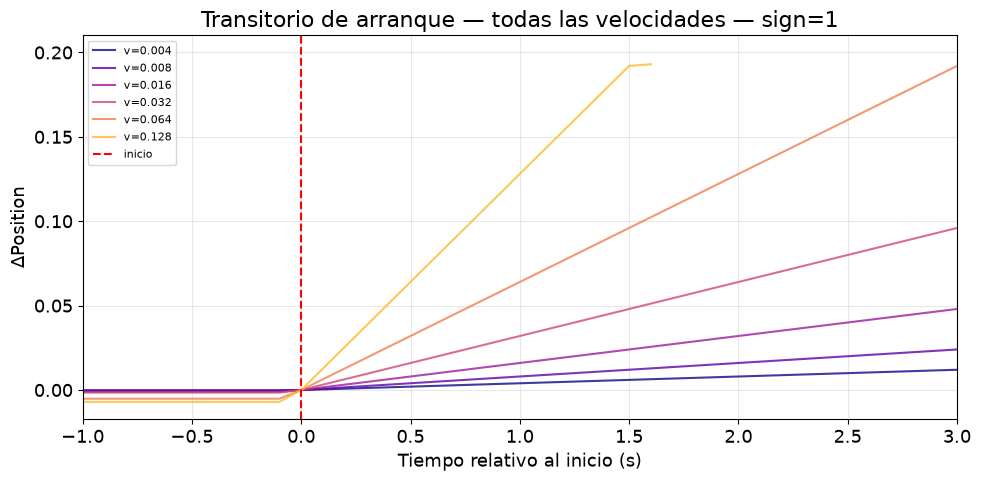

In [44]:
velocidades = sorted(segments_analysis["velocity"].unique())
colores_vel = plt.cm.plasma(np.linspace(0, 0.85, len(velocidades)))

fig, ax = plt.subplots(figsize=(10, 5))

n_pre = 30

for v, color in zip(velocidades, colores_vel):
    segs = segments_analysis[
        (segments_analysis["velocity"] == v) &
        (segments_analysis["sign"] == 1)
    ].copy()
    if len(segs) == 0:
        continue
    
    # coger el primer segmento de cada velocidad
    row = segs.iloc[0]
    seg_id = row["segment_id"]
    
    idx_seg = df.index[df["segment_id"] == seg_id]
    i0 = idx_seg.min()
    i1 = idx_seg.max()
    i_start = max(df.index.min(), i0 - n_pre)
    
    tmp = df.loc[i_start:i1].copy()
    t_rel = tmp["Time"].values - df.loc[i0, "Time"]
    pos = tmp["ActualPosition"].values - tmp["ActualPosition"].values[n_pre] if len(tmp) > n_pre else tmp["ActualPosition"].values
    
    ax.plot(t_rel, pos, color=color, linewidth=1.5, alpha=0.8, label=f"v={v}")

ax.axvline(0, color="red", linestyle="--", label="inicio")
ax.set_xlabel("Tiempo relativo al inicio (s)")
ax.set_ylabel("ΔPosition")
ax.set_title("Transitorio de arranque — todas las velocidades — sign=1")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_xlim(-1, 3)  # zoom en el arranque
plt.tight_layout()
plt.show()

Confirma que el arranque es limpio — todas las curvas arrancan en t=0 sin retraso visible. La separación entre líneas refleja simplemente las distintas velocidades, no un comportamiento anómalo.

                   t0         err_pend         err_sensor        
                 mean     std     mean     std       mean     std
velocity sign                                                    
0.004    -1.0 -0.0022  0.0009   0.0000  0.0001     0.4844  0.0219
          1.0 -0.0016  0.0014  -0.0000  0.0001    -0.5042  0.0183
0.008    -1.0 -0.0015  0.0010  -0.0000  0.0001     0.4701  0.0334
          1.0 -0.0002  0.0031   0.0001  0.0001    -0.5191  0.0391
0.016    -1.0 -0.0009  0.0006   0.0001  0.0002     0.3786  0.0461
          1.0 -0.0004  0.0017  -0.0001  0.0005    -0.6325  0.0582
0.032    -1.0 -0.0005  0.0006   0.0004  0.0007     0.0130  0.3313
          1.0 -0.0002  0.0010   0.0007  0.0005    -0.9142  0.1802
0.064    -1.0  0.0008  0.0031  -0.0006  0.0010    -1.8161  0.9543
          1.0 -0.0000  0.0010   0.0025  0.0016    -2.6438  1.0059
0.128    -1.0  0.0014  0.0041  -0.0034  0.0044    -8.3548  4.4775
          1.0  0.0007  0.0029   0.0096  0.0046    -8.3408  3.5879


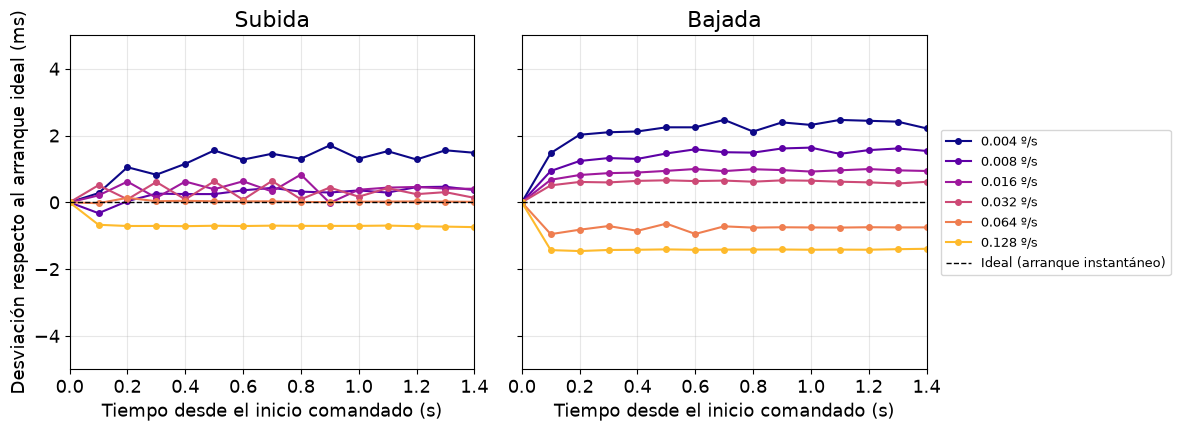

In [45]:
t_max = 1.4   # ventana tras el arranque (s)

filas, curvas = [], {}
for _, seg in segments_analysis.iterrows():
    idx = df.index[df["segment_id"] == seg["segment_id"]]
    i0, i1 = idx.min(), idx.max()
    t = df.loc[i0:i1, "Time"].values - df.loc[i0, "Time"]
    x = df.loc[i0:i1, "ActualPosition"].values - df.loc[i0, "ActualPosition"]
    n = len(t)
    if n < 8:
        continue
    a, b = np.polyfit(t[int(.3*n):int(.7*n)], x[int(.3*n):int(.7*n)], 1)
    filas.append({"velocity": seg["velocity"], "sign": seg["sign"],
                  "t0": -b / a,
                  "err_pend": (abs(a) - seg["velocity"]) * 1e3,
                  "err_sensor": (abs(seg["vel_mean"]) - seg["velocity"]) * 1e3})
    m = t <= t_max + 1e-9
    curvas.setdefault((seg["velocity"], seg["sign"]), []).append((t[m], x[m] / a - t[m]))

arr = pd.DataFrame(filas)
print(arr.groupby(["velocity", "sign"])[["t0", "err_pend", "err_sensor"]]
         .agg(["mean", "std"]).round(4).to_string())

velocidades = sorted(arr["velocity"].unique())
colores = plt.cm.plasma(np.linspace(0, 0.85, len(velocidades)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, s, titulo in zip(axes, [1, -1], ["Subida", "Bajada"]):
    for v, c in zip(velocidades, colores):
        lista = curvas.get((v, s), [])
        if not lista:
            continue
        L = min(len(tc) for tc, _ in lista)
        tc = lista[0][0][:L]
        dev = np.mean([d[:L] for _, d in lista], axis=0)
        ax.plot(tc, dev * 1e3, "o-", ms=4, color=c, label=f"{v} º/s")
    ax.axhline(0, color="k", ls="--", lw=1, label="Ideal (arranque instantáneo)")
    ax.set_xlim(0, t_max)
    ax.set_ylim(-5, 5)
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo desde el inicio comandado (s)")
    ax.grid(alpha=.3)
axes[0].set_ylabel("Desviación respecto al arranque ideal (ms)")
axes[1].legend(fontsize=9,loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
fig.savefig("fig7_arranque.pdf", bbox_inches="tight")

Esta es lo mismo pero normalizado. Lo que vemos es un solape de la línea ideal, confirmando que el arranque es proporcional a la velocidad.

#### Frenada — comparación entre velocidades

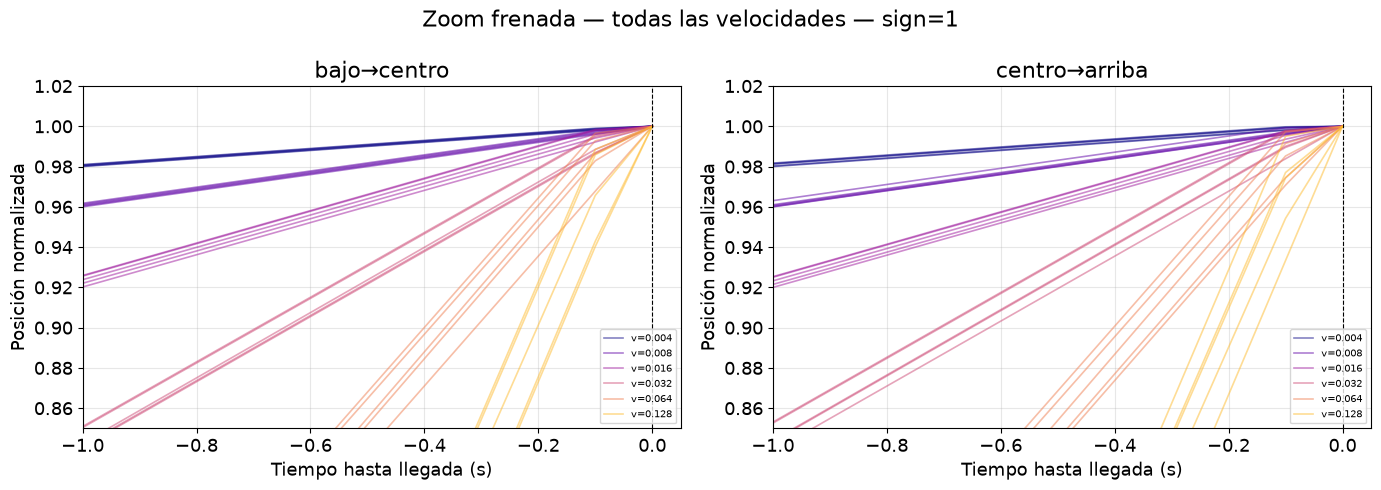

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, grupo_nombre in zip(axes, ["bajo→centro", "centro→arriba"]):
    for v, color in zip(velocidades, colores_vel):
        
        segs = segments_analysis[
            (segments_analysis["velocity"] == v) &
            (segments_analysis["sign"] == 1)
        ].copy()
        if len(segs) == 0:
            continue
        
        km = KMeans(n_clusters=2, random_state=0)
        segs["grupo"] = km.fit_predict(segs[["pos_ini"]])
        centros = segs.groupby("grupo")["pos_ini"].mean()
        mapa = {centros.idxmin(): "bajo→centro", centros.idxmax(): "centro→arriba"}
        segs["grupo"] = segs["grupo"].map(mapa)
        grupo_segs = segs[segs["grupo"] == grupo_nombre]
        
        for i, (_, row) in enumerate(grupo_segs.iterrows()):
            seg_data = df[df["segment_id"] == row["segment_id"]].copy()
            t_rel = seg_data["Time"].values - seg_data["Time"].values[-1]  # relativo al final
            pos_norm = seg_data["ActualPosition"].values - seg_data["ActualPosition"].values[0]
            pos_norm = pos_norm / pos_norm[-1] if pos_norm[-1] != 0 else pos_norm
            label = f"v={v}" if i == 0 else None
            ax.plot(t_rel, pos_norm, alpha=0.5, linewidth=1.2, color=color, label=label)
    
    ax.set_xlim(-1.0, 0.05)
    ax.set_ylim(0.85, 1.02)
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(grupo_nombre)
    ax.set_xlabel("Tiempo hasta llegada (s)")
    ax.set_ylabel("Posición normalizada")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle("Zoom frenada — todas las velocidades — sign=1")
plt.tight_layout()
plt.show()

Se observa un patrón claro y consistente en ambos grupos.
Las velocidades bajas 0.004,0.008, inician la desaceleracion mucho antes de llegar al destino, hasta 1 s antes.
Las altas como 0.064,0.128 mantienen la velocidad hasta más cerca del destino y frenan de forma más brusca los últimos 0.2-0.3 s.
El comportamiento si que es bastante simetrico entre bajo centro y centro arriba lo que indica mas bien que la dinamica del frenado depende de la velocidad comandada unicamente.

### Caracterización de la transición (frenada)

Mediante regresión lineal por tramos a cada segmento de movimiento se detecta el instante en el que la pendiente cambia (inicio de la desaceleración), y se mide la duración de la transición, para todas las velocidades.

In [47]:
#detectar breakpoint (punto de cambio)
from sklearn.linear_model import LinearRegression

def find_breakpoint(t, x, search_start=0.15, search_end=0.85):
    n = len(t)
    i_min = int(search_start * n)
    i_max = int(search_end * n)
    
    best_err = np.inf
    best_i = i_min
    
    for i in range(i_min, i_max):
        # tramo 1: de 0 a i
        t1 = t[:i].reshape(-1, 1)
        x1 = x[:i]
        # tramo 2: de i a n
        t2 = t[i:].reshape(-1, 1)
        x2 = x[i:]
        
        if len(t1) < 2 or len(t2) < 2:
            continue
        
        r1 = LinearRegression().fit(t1, x1)
        r2 = LinearRegression().fit(t2, x2)
        
        err = (
            np.sum((x1 - r1.predict(t1))**2) +
            np.sum((x2 - r2.predict(t2))**2)
        )
        
        if err < best_err:
            best_err = err
            best_i = i
    
    return best_i, best_err


velocidades = sorted(segments_analysis["velocity"].unique())
resultados_cambio = []

for v in velocidades:
    for s in [1, -1]:
        segs = segments_analysis[
            (segments_analysis["velocity"] == v) &
            (segments_analysis["sign"] == s)
        ].copy()
        
        for _, row in segs.iterrows():
            seg_data = df[df["segment_id"] == row["segment_id"]].copy()
            
            t = seg_data["Time"].values - seg_data["Time"].values[0]
            x = seg_data["ActualPosition"].values - seg_data["ActualPosition"].values[0]
            
            if len(t) < 10:
                continue
            
            bp_i, _ = find_breakpoint(t, x)
            
            t_bp = t[bp_i]                        # instante del cambio (s desde inicio)
            t_total = t[-1]                        # duración total del segmento
            t_transition = t_total - t_bp         # duración de la fase de frenada
            t_transition_pct = t_transition / t_total * 100  # en % del total
            
            resultados_cambio.append({
                "segment_id": row["segment_id"],
                "velocity": v,
                "sign": s,
                "t_total": t_total,
                "t_breakpoint": t_bp,
                "t_transition": t_transition,
                "t_transition_pct": t_transition_pct,
            })

cambio_df = pd.DataFrame(resultados_cambio)
display(cambio_df.groupby(["velocity", "sign"])[["t_total", "t_breakpoint", "t_transition", "t_transition_pct"]].mean().round(4))
    

t_total  t_breakpoint  t_transition  t_transition_pct
velocity sign                                                       
0.004    -1      50.00         42.36          7.64           15.2800
          1      50.00         36.96         13.04           26.0800
0.008    -1      25.00         20.46          4.54           18.1600
          1      25.00         18.27          6.73           26.9200
0.016    -1      12.50         10.60          1.90           15.2000
          1      12.50          9.71          2.79           22.3200
0.032    -1       6.24          4.97          1.27           20.3815
          1       6.24          4.83          1.41           22.6395
0.064    -1       3.13          2.63          0.50           15.9778
          1       3.14          2.42          0.72           23.0242
0.128    -1       1.57          1.17          0.40           25.7917
          1       1.57          1.17          0.40           25.7917

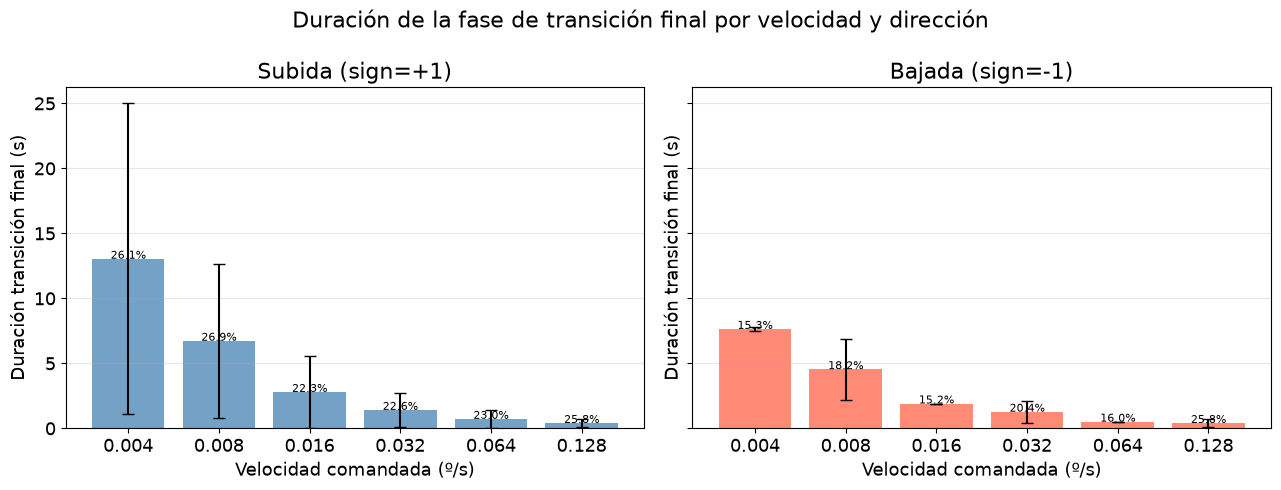

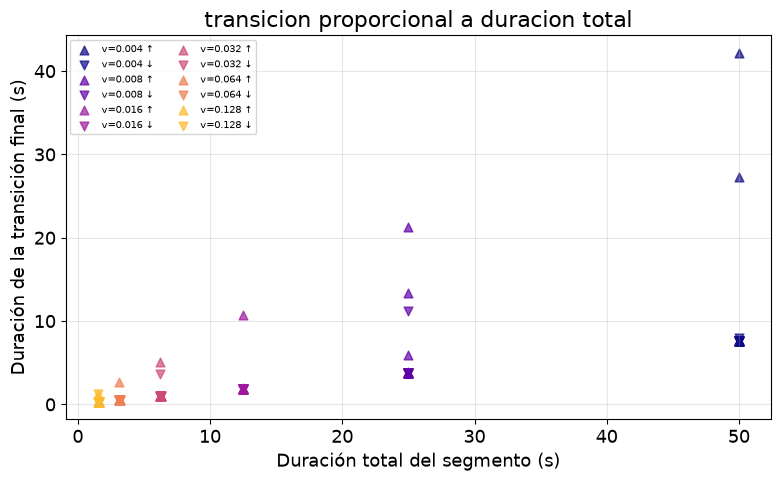

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, s, titulo in zip(axes, [1, -1], ["Subida (sign=+1)", "Bajada (sign=-1)"]):
    data = cambio_df[cambio_df["sign"] == s]
    
    resumen = data.groupby("velocity")[["t_transition", "t_transition_pct"]].agg(["mean", "std"])
    
    vels = resumen.index.values
    means = resumen[("t_transition", "mean")].values
    stds  = resumen[("t_transition", "std")].values
    
    ax.bar(range(len(vels)), means, yerr=stds, capsize=4,
           color="steelblue" if s == 1 else "tomato", alpha=0.75)
    ax.set_xticks(range(len(vels)))
    ax.set_xticklabels([str(v) for v in vels])
    ax.set_xlabel("Velocidad comandada (º/s)")
    ax.set_ylabel("Duración transición final (s)")
    ax.set_title(titulo)
    ax.grid(alpha=0.3, axis="y")
    
    # para q meta el % sobre cada barra 
    pcts = resumen[("t_transition_pct", "mean")].values
    for i, (m, p) in enumerate(zip(means, pcts)):
        ax.text(i, m + 0.01, f"{p:.1f}%", ha="center", fontsize=8)

plt.suptitle("Duración de la fase de transición final por velocidad y dirección")
plt.tight_layout()
plt.show()

#  t_transition vs t_total para ver si es proporcional ---
fig, ax = plt.subplots(figsize=(8, 5))
colores_vel = plt.cm.plasma(np.linspace(0, 0.85, len(velocidades)))

for v, color in zip(velocidades, colores_vel):
    for s, marker in zip([1, -1], ["^", "v"]):
        data = cambio_df[(cambio_df["sign"] == s) & (cambio_df["velocity"] == v)]
        label = f"v={v} {'↑' if s==1 else '↓'}"
        ax.scatter(data["t_total"], data["t_transition"],
                   alpha=0.7, s=40, color=color, marker=marker, label=label)

ax.set_xlabel("Duración total del segmento (s)")
ax.set_ylabel("Duración de la transición final (s)")
ax.set_title("transicion proporcional a duracion total")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La subida tarda más en frenar que la bajada. En porcentaje la subida usa un 22-27% del tiempo en la transicion del final y la bajada un 15-20%, lo que es lo mismo que se había mencionado antes de que la subida tiene una desaceleración más pronunciada.
Luego, en la grafica de scatter podemos ver como , dentro de cada color (que se corresponde con cada velocidad), el triángulo hacia arriba que representa la subida está siempre más arriba que el triángulo invertido.

In [49]:
## cómo de "brusco" es el cambio? Tasa de cambio de pendiente.

resultados_tasa = []

for v in velocidades:
    for s in [1, -1]:
        segs = segments_analysis[
            (segments_analysis["velocity"] == v) &
            (segments_analysis["sign"] == s)
        ].copy()

        for _, row in segs.iterrows():
            seg_data = df[df["segment_id"] == row["segment_id"]].copy()

            t = seg_data["Time"].values - seg_data["Time"].values[0]
            x = seg_data["ActualPosition"].values - seg_data["ActualPosition"].values[0]

            if len(t) < 10:
                continue

            bp_i, _ = find_breakpoint(t, x)

            t1 = t[:bp_i].reshape(-1, 1)
            x1 = x[:bp_i]
            t2 = t[bp_i:].reshape(-1, 1)
            x2 = x[bp_i:]

            if len(t1) < 2 or len(t2) < 2:
                continue

            slope_central = LinearRegression().fit(t1, x1).coef_[0]
            slope_final   = LinearRegression().fit(t2, x2).coef_[0]

            tasa_cambio_pendiente = abs(slope_central - slope_final) / abs(slope_central) if slope_central != 0 else np.nan

            resultados_tasa.append({
                "segment_id": row["segment_id"],
                "velocity": v,
                "sign": s,
                "slope_central": slope_central,
                "slope_final": slope_final,
                "tasa_cambio_pendiente": tasa_cambio_pendiente,
            })

tasa_df = pd.DataFrame(resultados_tasa)
display(tasa_df.groupby(["velocity", "sign"])[["slope_central", "slope_final", "tasa_cambio_pendiente"]].mean().round(4))


slope_central  slope_final  tasa_cambio_pendiente
velocity sign                                                   
0.004    -1           -0.004      -0.0040                 0.0006
          1            0.004       0.0040                 0.0004
0.008    -1           -0.008      -0.0080                 0.0020
          1            0.008       0.0080                 0.0009
0.016    -1           -0.016      -0.0159                 0.0061
          1            0.016       0.0159                 0.0064
0.032    -1           -0.032      -0.0316                 0.0130
          1            0.032       0.0313                 0.0204
0.064    -1           -0.064      -0.0599                 0.0634
          1            0.064       0.0592                 0.0754
0.128    -1           -0.128      -0.1123                 0.1222
          1            0.128       0.1095                 0.1443

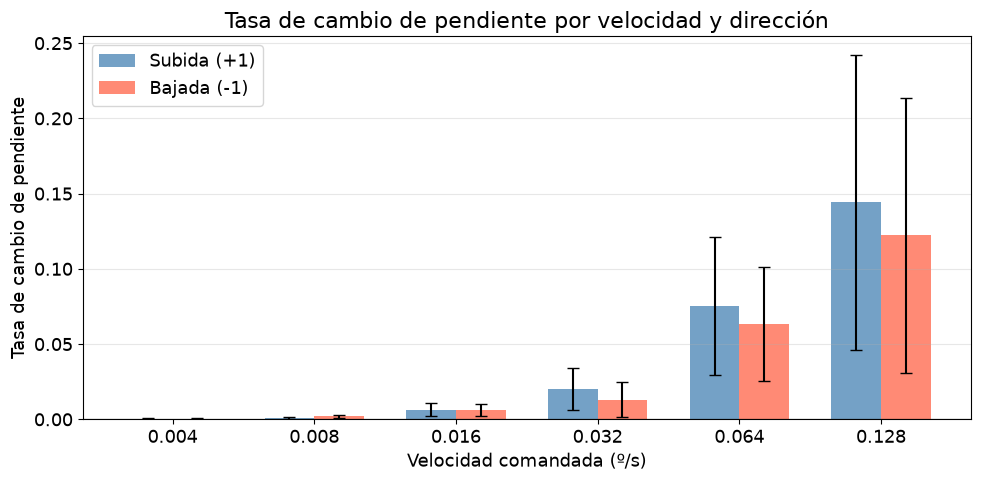

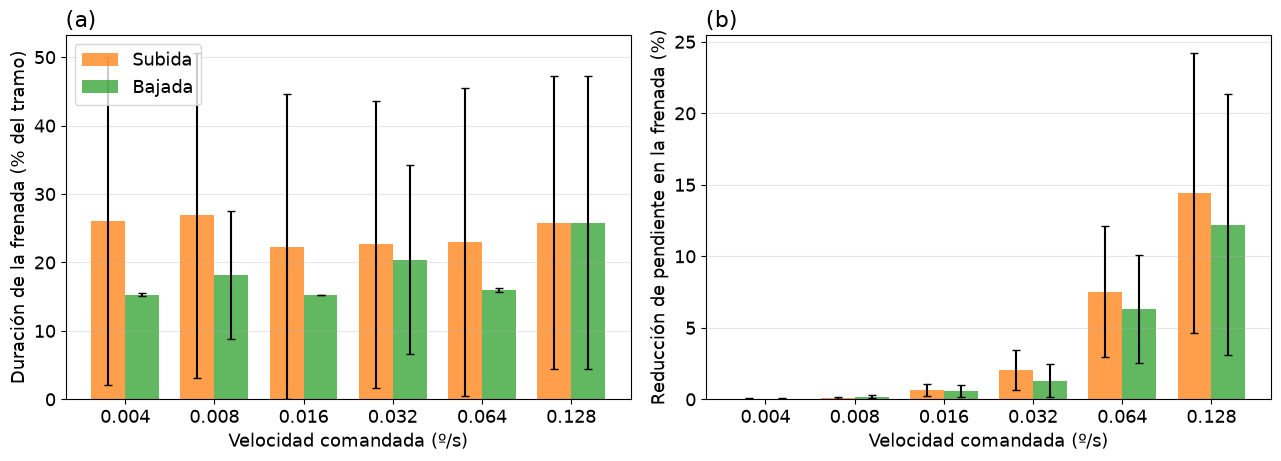

In [50]:
fig, ax = plt.subplots(figsize=(10, 5))

resumen_tasa = tasa_df.groupby(["velocity", "sign"])["tasa_cambio_pendiente"].agg(["mean", "std"]).reset_index()

x = np.arange(len(velocidades))
width = 0.35

for i, (s, color, label) in enumerate([(1, "steelblue", "Subida (+1)"), (-1, "tomato", "Bajada (-1)")]):
    datos = resumen_tasa[resumen_tasa["sign"] == s].set_index("velocity")
    means = [datos.loc[v, "mean"] if v in datos.index else 0 for v in velocidades]
    stds  = [datos.loc[v, "std"]  if v in datos.index else 0 for v in velocidades]
    ax.bar(x + i*width, means, width, yerr=stds, capsize=4,
           color=color, alpha=0.75, label=label)

ax.set_xticks(x + width/2)
ax.set_xticklabels([str(v) for v in velocidades])
ax.set_xlabel("Velocidad comandada (º/s)")
ax.set_ylabel("Tasa de cambio de pendiente")
ax.set_title("Tasa de cambio de pendiente por velocidad y dirección")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()






fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(velocidades))
w = 0.38

for i, (s, color, label) in enumerate([(1, "tab:orange", "Subida"),
                                       (-1, "tab:green", "Bajada")]):
    pos = x + (i - 0.5) * w

    # (a) Duración de la frenada (% del tramo)
    r = (cambio_df[cambio_df["sign"] == s]
         .groupby("velocity")["t_transition_pct"]
         .agg(["mean", "std"]).reindex(velocidades))
    ax1.bar(pos, r["mean"], w, yerr=r["std"], capsize=3,
            color=color, alpha=0.75, label=label)

    # (b) Reducción de pendiente en la frenada
    t = (tasa_df[tasa_df["sign"] == s]
         .groupby("velocity")["tasa_cambio_pendiente"]
         .agg(["mean", "std"]).reindex(velocidades))
    ax2.bar(pos, t["mean"] * 100, w, yerr=t["std"] * 100, capsize=3,
            color=color, alpha=0.75, label=label)

for ax, tit in [(ax1, "(a)"), (ax2, "(b)")]:
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in velocidades])
    ax.set_xlabel("Velocidad comandada (º/s)")
    ax.set_title(tit, loc="left")
    ax.grid(alpha=0.3, axis="y")
ax1.set_ylabel("Duración de la frenada (% del tramo)")
ax2.set_ylabel("Reducción de pendiente en la frenada (%)")
ax1.legend()
fig.tight_layout()
fig.savefig("fig8_frenada.pdf", bbox_inches="tight")

slope_central reproduce la velocidad comandada en todos los casos (es eso). La tasa de cambio pendiente es muy pequeña y casi no se aprecia para velocidades bajas (cambio practicamente imperceptible) a velocidades altas es apreciable pero sigue siendo moderado, nunca llega a 1 que serñia el máximo ratio porque estamos hablando de un cociente, ni se aproxima.
De la gráfica también se deduce que la subida está siempre por encima de la bajada consistente con lo que se comentaba antes.

### Histéresis en el punto 0 (análisis complementario)

Se analiza si el sistema llega al mismo punto cuando se aproxima desde direcciones opuestas, para v=0.032 y, posteriormente, para las 6 velocidades comandadas.

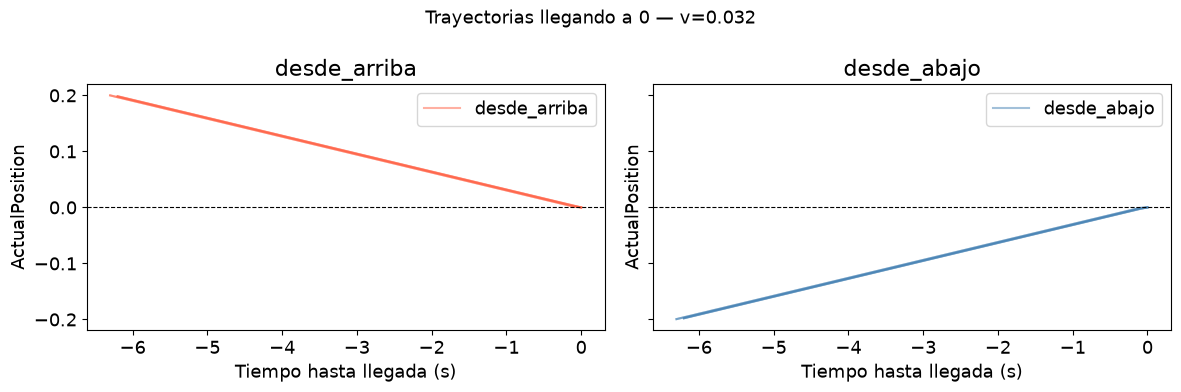

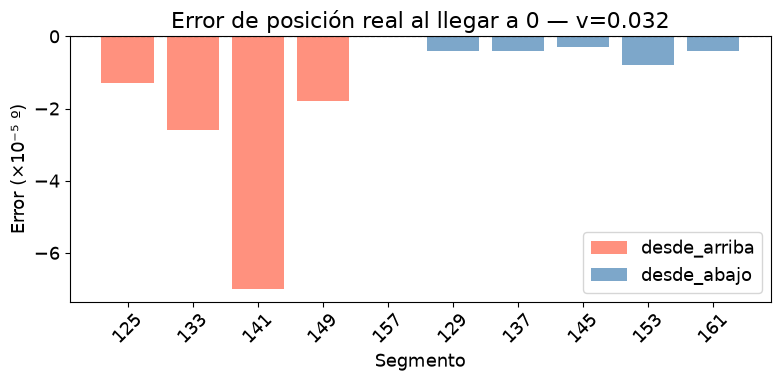

=== Indicador de histéresis ===
              Error medio (º)  Desviación std (º)
origen                                           
desde_abajo         -0.000005            0.000002
desde_arriba        -0.000025            0.000027

Histéresis (diferencia de medias): 2.08e-05 º


In [51]:
#histeresis: llegada a 0
from sklearn.cluster import KMeans

v_target = 0.032
colores = {"desde_arriba": "tomato", "desde_abajo": "steelblue"}

#segmentos que llegan a 0 desde esa velocidad y el 0.01 es por los que quedan cerca de 0
segs_llegan_0 = segments_analysis[(segments_analysis["velocity"] == v_target) &(segments_analysis["pos_fin"].abs() < 0.01)].copy()

segs_llegan_0["origen"] = segs_llegan_0.apply(lambda r: "desde_arriba" if r["sign"] == -1 else "desde_abajo", axis=1)

segs_llegan_0["actual_fin"] = segs_llegan_0["segment_id"].apply(lambda sid: df[df["segment_id"] == sid]["ActualPosition"].iloc[-1])

#Gráfica 1: trayectorias superpuestas llegando a 0 
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (origen, color) in zip(axes, colores.items()):
    grupo = segs_llegan_0[segs_llegan_0["origen"] == origen]
    for i, (_, row) in enumerate(grupo.iterrows()):
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()
        t_rel = seg_data["Time"].values - seg_data["Time"].values[-1]
        pos = seg_data["ActualPosition"].values
        label = origen if i == 0 else None
        ax.plot(t_rel, pos, alpha=0.5, linewidth=1.5, color=color, label=label)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(origen)
    ax.set_xlabel("Tiempo hasta llegada (s)")
    ax.set_ylabel("ActualPosition")
    ax.legend()
plt.suptitle(f"Trayectorias llegando a 0 — v={v_target}", fontsize=13)
plt.tight_layout()
plt.show()

# Gráfica 2: error real por segmento 
fig, ax = plt.subplots(figsize=(8, 4))
for origen, color in colores.items():
    grupo = segs_llegan_0[segs_llegan_0["origen"] == origen].copy()
    ax.bar(grupo["segment_id"].astype(str), grupo["actual_fin"] * 1e5,
           color=color, alpha=0.7, label=origen)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title(f"Error de posición real al llegar a 0 — v={v_target}")
ax.set_xlabel("Segmento")
ax.set_ylabel("Error (×10⁻⁵ º)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# indicador numerico
resumen = segs_llegan_0.groupby("origen")["actual_fin"].agg(["mean","std"])
resumen.columns = ["Error medio (º)", "Desviación std (º)"]
print("=== Indicador de histéresis ===")
print(resumen.to_string())
print()
histeresis = abs(
    segs_llegan_0[segs_llegan_0["origen"]=="desde_arriba"]["actual_fin"].mean() -
    segs_llegan_0[segs_llegan_0["origen"]=="desde_abajo"]["actual_fin"].mean()
)
print(f"Histéresis (diferencia de medias): {histeresis:.2e} º")

Las trayectorias muestran un sistema repetible en ambas direcciones, ya que los ciclos se solapan al llegar desde arriba y desde abajo. La histéresis es la diferencia entre el error medio de llegada al 0 desde arriba (-2.5e-5 º) y desde abajo (-0.5e-5 º); el valor resultante (~2e-5 º) es muy pequeño en términos absolutos.

### Zoom en la llegada al punto 0

Se hace zoom en los últimos instantes antes de llegar al destino para visualizar 
si existe separación entre las trayectorias de ambas direcciones.

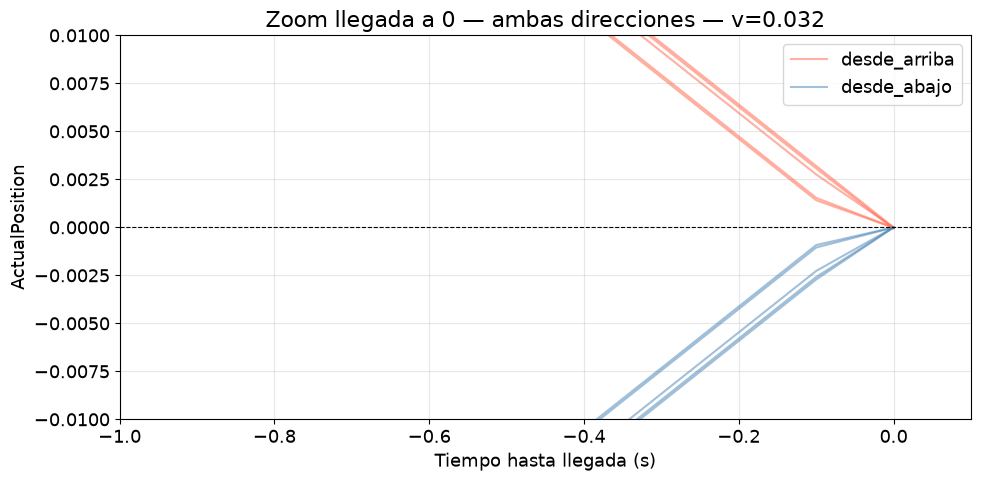

In [52]:
fig, ax = plt.subplots(figsize=(10, 5))

for origen, color in colores.items():
    grupo = segs_llegan_0[segs_llegan_0["origen"] == origen]
    for i, (_, row) in enumerate(grupo.iterrows()):
        seg_data = df[df["segment_id"] == row["segment_id"]].copy()
        t_rel = seg_data["Time"].values - seg_data["Time"].values[-1]
        pos = seg_data["ActualPosition"].values
        label = origen if i == 0 else None
        ax.plot(t_rel, pos, alpha=0.5, linewidth=1.5, color=color, label=label)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlim(-1, 0.1)   # zoom últimos 1s
ax.set_ylim(-0.01, 0.01)  # zoom cerca del 0
ax.set_title(f"Zoom llegada a 0 — ambas direcciones — v={v_target}")
ax.set_xlabel("Tiempo hasta llegada (s)")
ax.set_ylabel("ActualPosition")
ax.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Las lineas desde arriba y desde abajo son simetricas pero no se solapan, sino que hay una separacion visible entre ellas y eso confirma la histeresis, se puede ver que desde abajo llega al 0 un poco antes que desde arriba.

### Extensión a todas las velocidades

Se repite el cálculo del indicador de histéresis para las 6 velocidades comandadas 
para ver si la histéresis varía con la velocidad.

Se analiza el error de posicionamiento real (ActualPosition final - target) 
al llegar al punto 0 desde ambas direcciones, para todas las velocidades comandadas.

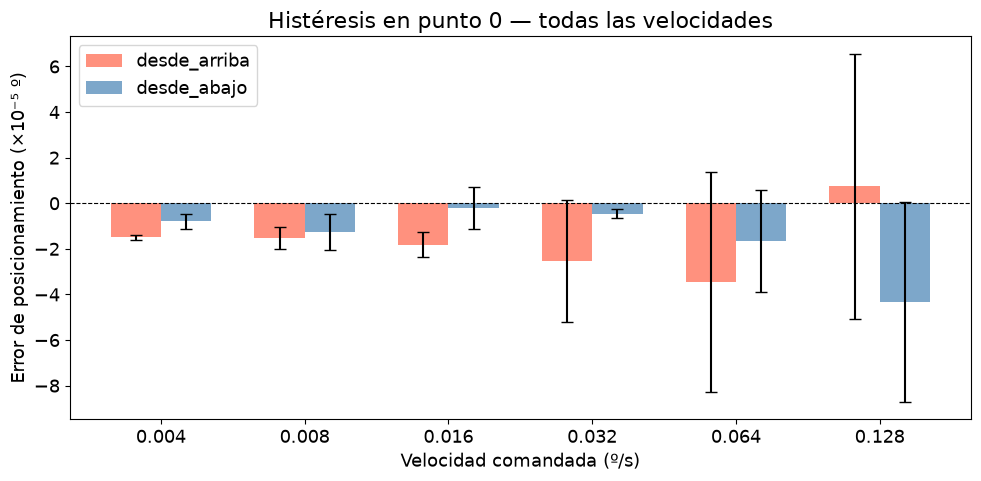

origen    desde_abajo  desde_arriba  histéresis (×10⁻⁵ )
velocity                                                
0.004           -0.80         -1.50                 0.70
0.008           -1.26         -1.52                 0.26
0.016           -0.20         -1.82                 1.62
0.032           -0.46         -2.54                 2.08
0.064           -1.66         -3.44                 1.78
0.128           -4.32          0.74                 5.06
origen    desde_abajo  desde_arriba  histeresis
velocity                                       
0.004           -0.80         -1.50        0.70
0.008           -1.26         -1.52        0.26
0.016           -0.20         -1.82        1.62
0.032           -0.46         -2.54        2.08
0.064           -1.66         -3.44        1.78
0.128           -4.32          0.74        5.06


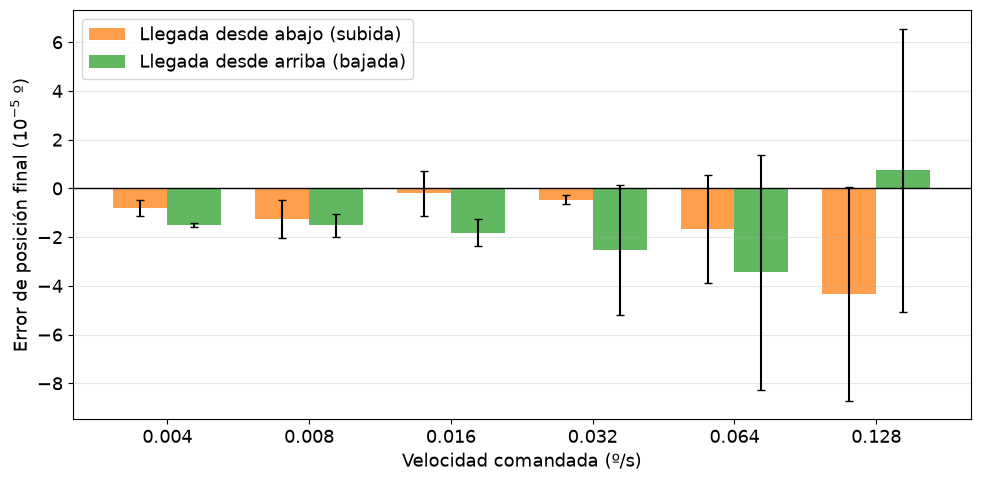

In [53]:
# HISTÉRESIS PARA TODAS LAS VELOCIDADES
velocidades = sorted(segments_analysis["velocity"].unique())
resultados_hist = []

for v in velocidades:
    segs = segments_analysis[
        (segments_analysis["velocity"] == v) &
        (segments_analysis["pos_fin"].abs() < 0.01)
    ].copy()
    
    if len(segs) < 2:
        continue
    
    segs["origen"] = segs.apply(
        lambda r: "desde_arriba" if r["sign"] == -1 else "desde_abajo", axis=1
    )
    segs["actual_fin"] = segs["segment_id"].apply(
        lambda sid: df[df["segment_id"] == sid]["ActualPosition"].iloc[-1]
    )
    
    for origen in ["desde_arriba", "desde_abajo"]:
        grupo = segs[segs["origen"] == origen]["actual_fin"]
        if len(grupo) > 0:
            resultados_hist.append({
                "velocity": v,
                "origen": origen,
                "mean": grupo.mean(),
                "std": grupo.std()
            })

df_hist = pd.DataFrame(resultados_hist)

# --- Gráfica: error medio por velocidad y dirección ---
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(velocidades))
width = 0.35

for i, origen in enumerate(["desde_arriba", "desde_abajo"]):
    color = "tomato" if origen == "desde_arriba" else "steelblue"
    datos = df_hist[df_hist["origen"] == origen].set_index("velocity")
    means = [datos.loc[v, "mean"] * 1e5 if v in datos.index else 0 for v in velocidades]
    stds  = [datos.loc[v, "std"] * 1e5 if v in datos.index else 0 for v in velocidades]
    ax.bar(x + i*width, means, width, yerr=stds, label=origen,
           color=color, alpha=0.7, capsize=4)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(x + width/2)
ax.set_xticklabels([str(v) for v in velocidades])
ax.set_xlabel("Velocidad comandada (º/s)")
ax.set_ylabel("Error de posicionamiento (×10⁻⁵ º)")
ax.set_title("Histéresis en punto 0 — todas las velocidades")
ax.legend()
plt.tight_layout()
plt.show()

# --- Tabla resumen ---
pivot_mean = df_hist.pivot(index="velocity", columns="origen", values="mean") * 1e5
pivot_std  = df_hist.pivot(index="velocity", columns="origen", values="std") * 1e5
pivot_hist = (pivot_mean["desde_arriba"] - pivot_mean["desde_abajo"]).abs()
pivot_mean["histéresis (×10⁻⁵ )"] = pivot_hist
print(pivot_mean.round(2).to_string())






fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(velocidades))
w = 0.38

for i, (origen, color, label) in enumerate([
        ("desde_abajo",  "tab:orange", "Llegada desde abajo (subida)"),
        ("desde_arriba", "tab:green",  "Llegada desde arriba (bajada)")]):
    d = df_hist[df_hist["origen"] == origen].set_index("velocity").reindex(velocidades)
    ax.bar(x + (i - 0.5) * w, d["mean"] * 1e5, w, yerr=d["std"] * 1e5,
           capsize=3, color=color, alpha=0.75, label=label)

ax.axhline(0, color="k", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([str(v) for v in velocidades])
ax.set_xlabel("Velocidad comandada (º/s)")
ax.set_ylabel(r"Error de posición final ($10^{-5}$ º)")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig("fig9_histeresis.pdf", bbox_inches="tight")

# Tabla para comprobar la Tabla 2 de la memoria
tabla = df_hist.pivot(index="velocity", columns="origen", values="mean") * 1e5
tabla["histeresis"] = (tabla["desde_abajo"] - tabla["desde_arriba"]).abs()
print(tabla.round(2).to_string())

## e. Conclusiones



**Comportamiento dinámico:**
- En el arranque, todas las velocidades siguen la línea ideal sin desviación apreciable (limitado por la resolución temporal del ensayo).
- En la frenada, la subida emplea un 22–27% del tiempo del tramo en la transición final, frente a un 15–20% en la bajada: la subida tiene una desaceleración más pronunciada.
- La pendiente en régimen central reproduce fielmente la velocidad impuesta en todos los casos. En la fase final, el cociente entre pendiente final y central cae al 85–88% (subida) y 90–93% (bajada), efecto que se acentúa con la velocidad.

**Histéresis:**
- Para velocidades bajas y medias (0.004 a 0.064 º/s) la histéresis es pequeña y consistente (0.26–2.08 ×10⁻⁵ º), llegando el sistema sistemáticamente algo más lejos desde abajo que desde arriba.
- A v=0.128 º/s la histéresis aumenta a 5.06 ×10⁻⁵ º y el patrón se invierte, con mayor dispersión: el sistema pierde precisión de posicionamiento en el punto 0 a la velocidad más alta.
- En todos los casos los errores son del orden de micrómetros: el sistema tiene una precisión de posicionamiento muy alta en todo el rango estudiado.

### Velocidad seleccionada



La velocidad v=0.008 da el valor menor para el error medio y el error relativo, la dispersión empieza a degradarse a partir de v=0.064.

La velocidad v=0.008 da el valor menor para el error medio y el error relativo, la dispersión empieza a degradarse a partir de v=0.064.